# Joint moment tensor and DC-directivity inversion: theory and a synthetic example

This notebook is the theoretical and synthetic example for the joint inversion of a seismic moment tensor (MT), a corner frequency and a rupture velocity vector, `unshake.MTDCDirectivityModel`. It makes the paper figures and tables.

**What it does:**
1. **Theory** (sections 1–3): the forward problem (Green's functions, the combined isotropic + directivity source time function), the inverse problem, and the four solution methods.
2. **Synthetic set-up** (sections 4–5): a homogeneous crustal full space with absorbing boundaries on all sides, so the data are body waves only. An earthquake at 1 km depth is recorded by two rings of 50 three-component receivers (1 km and 3 km diameter) centred on the epicentre. The six elementary MT Green's functions are computed **once**, up to 25 Hz: by default from the exact analytic full-space solution, or optionally simulated with Salvus.
3. **Three test sources** (section 6), all built from the same Green's functions:
   - **A**, DC-dominant, unilateral rupture;
   - **B**, tensile-crack-dominant, unilateral rupture;
   - **C**, the same MT as A but a **bilateral** rupture, inverted with the unilateral model (a model-error test).
4. **Inversions and figures** (sections 7–10). Each source is inverted by the variable-projection starting model, Monte Carlo (MC), non-linear least squares (NLLS) and MCMC. Per source, the figures are:
   - prior vs posterior marginals;
   - beachballs and lune plots;
   - example waveforms.
   Section 10 summarises all sources in figures and tables.

**Run time.** With the default analytic GFs, the GFs take seconds. The inversions take a few minutes per source, and are cached in `mt_dc_directivity_out/`. With the cache, the whole notebook re-runs in under a minute, which is convenient for editing figures. The optional Salvus runs are also cached, but take of the order of an hour on a laptop.

**Green's functions.** Set `GF_SOURCE` in section 4 (or the environment variable `UNSHAKE_GF_SOURCE`):
- `'analytic'` (the default) uses the exact homogeneous full-space solution (Aki & Richards 2002, eq. 4.29). It needs no Salvus, and has no numerical error.
- `'salvus'` uses six 3-D spectral-element simulations (Salvus), with attenuation. This shows the workflow needed for realistic (heterogeneous) media, where no analytic solution exists.

Section 5.3 compares the two when Salvus GFs are used.

Figures are written as PDF and PNG to `mt_dc_directivity_out/figures/`, and tables as CSV and LaTeX.

## 1. Theory: the forward problem

### 1.1 Formal band-limited Green's functions
For a point source with moment tensor $M_{pq}$ and a common moment-rate function, trace $i$ (one component of one receiver, here velocity) is

$$u_i(t) = \sum_{k=1}^{6} m_k\, \big[G_{ik} * \dot{s}\big](t), \qquad \mathbf{m} = [M_{nn}, M_{ee}, M_{dd}, M_{ne}, M_{nd}, M_{ed}]\ \text{(NED)},$$

where $G_{ik}$ is the response of trace $i$ to a unit-impulse moment rate of MT component $k$, and $\dot s(t)$ is the moment-rate function (unit moment).

How we compute $G_{ik}$:
- **Six elementary simulations.** One Salvus simulation per MT component, $M_{xx}, M_{yy}, M_{zz}, M_{xy}, M_{xz}, M_{yz}$ (ENU), each with a broadband wavelet $w(t)$. Salvus applies $w$ as the moment, so the output is $G * \dot w$.
- **Formal GFs.** We divide out the wavelet's moment rate in the frequency domain and apply a band filter $B(f)$:
$$\hat G_{ik}(f) \leftarrow \frac{B(f)}{\hat{\dot w}(f)}\,\widehat{(G_{ik} * \dot w)}(f)$$
(`forward.remove_stf`). $B$ is a cosine-tapered flat band, (1, 2, 20, 23) Hz here, set inside the wavelet's band and below the 25 Hz mesh limit, so the division is stable without a water level. The data are band-limited by the same $B$ (`forward.bandlimit`), so the source time function (STF) is the only source-time term in the forward model.
- **Linearity.** The GFs are linear in $\mathbf{m}$, and independent of the STF. **The six simulations are therefore run once and reused for every source and every STF**, including all the test sources here and every forward evaluation in the inversions.
- **Coordinates.** The Salvus components are reordered to NED, $[nn, ee, dd, ne, nd, ed] = [M_{yy}, M_{xx}, M_{zz}, M_{xy}, -M_{yz}, -M_{xz}]$. The receiver components are rotated to Z (up), R (radial) and T (transverse).

### 1.2 Splitting the moment tensor
We split $\mathbf{M}$ into a double-couple (DC) part and the rest, following Vavryčuk (2015). With eigenvalues $\lambda_1 \ge \lambda_2 \ge \lambda_3$ and T and P axes $\mathbf{e}_1$, $\mathbf{e}_3$:

$$M_{DC} = \tfrac12\big(\lambda_1-\lambda_3-|\lambda_1+\lambda_3-2\lambda_2|\big), \qquad
\mathbf{M}^{DC} = M_{DC}\,(\mathbf{e}_1\mathbf{e}_1^\mathsf{T}-\mathbf{e}_3\mathbf{e}_3^\mathsf{T}), \qquad
\mathbf{M}^{nDC} = \mathbf{M}-\mathbf{M}^{DC}\ \ (\text{ISO + CLVD}).$$

The DC fraction is $C_{DC} = M_{DC}/(|M_{ISO}|+|M_{CLVD}|+M_{DC})$, with $M_{ISO} = \tfrac13\sum\lambda$ and $M_{CLVD} = \tfrac23(\lambda_1+\lambda_3-2\lambda_2)$. $C_{DC}$ depends only on the lune position $(\gamma, \delta)$ (Tape & Tape 2012).

### 1.3 The combined isotropic + directivity source time function
- **Physical idea.** Directivity comes from a propagating shear rupture, so it belongs to the DC (shear) part of the source. Volumetric and tensile (ISO + CLVD) components are taken to radiate symmetrically.
- **The two STFs.** Each part gets its own causal Brune moment-rate STF, with a shared corner frequency $f_{c0}$:
$$\dot M(t; f_c) = \omega_c^2\, t\, e^{-\omega_c t} H(t), \qquad S(f; f_c) = \frac{1}{(1 + i f/f_c)^2}, \qquad \omega_c = 2\pi f_c.$$
  - **Non-DC part:** its STF is *isotropic* (direction-independent): $S(f; f_{c0})$ at every receiver.
  - **DC part:** its STF is Doppler-shifted by a unilateral rupture with velocity vector $\mathbf{v} = (v_E, v_N, v_U)$:
$$f_{c2,i} = \frac{f_{c0}}{1 - \mathbf{v}\cdot\hat{\mathbf{r}}_i / c_i},$$
    where $\hat{\mathbf{r}}_i$ is the straight-ray take-off vector to receiver $i$ (`Dataset.ray_dirs`) and $c_i$ a phase velocity ($c_i = v_p$ here).

The forward model is then

$$\boxed{\;u_i(t) = \mathcal{F}^{-1}\Big[\,S\big(f; f_{c2,i}\big)\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{DC}\big] \;+\; S(f; f_{c0})\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{nDC}\big]\Big]\;}$$

with zero-padded FFTs, so the convolution is linear (`MTDCDirectivityModel.forward`). An equivalent form,
$u_i = S(f_{c0})\,\mathbf{G}_i\cdot\mathbf{m} + \big[S(f_{c2,i}) - S(f_{c0})\big]\,\mathbf{G}_i\cdot\mathbf{m}^{DC}$,
shows that directivity is a perturbation acting only on the DC radiation.

**Properties:**
- **No free weight.** How much of the wavefield is directional is set by the MT itself, through $\mathbf{m}^{DC}$ and its radiation pattern at each receiver. This removes the trade-off between a free directional weight and $|\mathbf{v}|$.
- **Limits.**
  - $\mathbf{v} = 0$ gives a single Brune STF at $f_{c0}$.
  - A pure DC is fully directional.
  - A pure ISO, CLVD or tensile crack ($C_{DC} = 0$) has no sensitivity to $\mathbf{v}$.
- **Parameters (10):** $\mathbf{p} = [\mathbf{m}\ (6),\ f_{c0},\ v_E, v_N, v_U]$. The velocity-vector form has no coordinate singularity at $|\mathbf{v}| = 0$. Rupture speed, azimuth and plunge are derived for reporting.
- **First-order sensitivity.** For small $\mathbf{v}\cdot\hat{\mathbf{r}}/c$,
$$S(f; f_{c2,i}) \approx S(f; f_{c0}) + \frac{\mathbf{v}\cdot\hat{\mathbf{r}}_i}{c}\,K(f), \qquad K = f_{c0}\,\partial S/\partial f_{c0} = \frac{2 i x}{(1+ix)^3},\ x = f/f_{c0}.$$
The data therefore constrain the projections $\mathbf{v}\cdot\hat{\mathbf{r}}_i$, weighted by the DC radiation at each receiver.

### 1.4 Unilateral vs bilateral rupture (source C)
- **Definition.** A bilateral rupture of the same total length $L$ and rupture speed is two halves of length $L/2$ that start together and run in opposite directions, $\pm\mathbf{v}$. Each half has half the moment and half the duration, so its corner frequency is $2f_{c0}$:
$$S^{bi}_i(f) = \tfrac12\Big[S\Big(f; \frac{2f_{c0}}{1 - \mathbf{v}\cdot\hat{\mathbf{r}}_i/c}\Big) + S\Big(f; \frac{2f_{c0}}{1 + \mathbf{v}\cdot\hat{\mathbf{r}}_i/c}\Big)\Big].$$
- **Why the unilateral model can't fit it.** By the first-order expansion above, the $\pm$ terms cancel: $S^{bi} = S(f; 2f_{c0}) + O\big((\mathbf{v}\cdot\hat{\mathbf{r}}/c)^2\big)$. A bilateral rupture therefore looks, to first order, like a *non-directional* source with twice the corner frequency. Its remaining directivity is even in $\mathbf{v}\cdot\hat{\mathbf{r}}$, so the odd (unilateral) Doppler term cannot fit it.
- **Expectation.** Inverting source C with the unilateral model should give $f_{c0} \approx 2 f_{c0}^{true}$ and a small $|\mathbf{v}|$ that is not physically meaningful.

## 2. Theory: the inverse problem

**Likelihood.** Gaussian, with one noise level $\sigma$ shared by all $N = n_{tr} n_t$ samples:

$$\log L(\mathbf{d}\,|\,\mathbf{p}) = -\frac{1}{2\sigma_{\rm eff}^2} \sum_i \sum_t \big(d_i(t) - u_i(t; \mathbf{p})\big)^2 + \text{const}.$$

**Correlated noise.** The noise is band-limited by $B$, so neighbouring time samples are correlated, and the effective number of independent samples is $n_{\rm eff} < n_t$. Treating every sample as independent would make the posterior too narrow. We therefore use

$$\sigma_{\rm eff} = \sigma\sqrt{n_t/n_{\rm eff}}, \qquad n_t/n_{\rm eff} = n_f \frac{\sum_f P^2(f)}{\big(\sum_f P(f)\big)^2},$$

where $P(f)$ is the power spectrum of the residual (`misfit.noise_correlation_factor`). The factor is exact for flat-band noise, and about 2.5 here.

**Prior.** MCMC uses `MTDCDirectivityModel.log_prior`:
- the MT components: flat within $|m_k| \le 3\,\|\mathbf{m}_0\|$;
- $f_{c0}$: log-uniform over 1–30 Hz;
- $\mathbf{v}$: isotropic zero-mean Gaussian, $\sigma_v = 0.5\,v_s$, truncated at $|\mathbf{v}| \le v_{max} = 0.9\,v_s$ (sub-shear).

The Gaussian on $\mathbf{v}$ is smooth at $\mathbf{v} = 0$, and its mean, $\mathbf{v} = 0$, is the "no directivity" answer where the data carry no information on $\mathbf{v}$. (A uniform prior on the ball $|\mathbf{v}| \le v_{max}$ would imply $p(|\mathbf{v}|) \propto |\mathbf{v}|^2$, favouring fast ruptures.)

**What is non-linear.** The model is linear in the MT amplitude ($\mathbf{m}^{DC}$ is homogeneous of degree 1). It is non-linear in the MT shape and orientation, in $f_{c0}$ and in $\mathbf{v}$.

## 3. Theory: solution methods

1. **Starting model, by variable projection.**
   - For a trial $f_{c0}$, the GFs are convolved with one Brune STF, and $\mathbf{m}$ is solved by linear least squares. The residual is then a function of $f_{c0}$ alone.
   - A 15-point log scan plus a bounded 1-D refinement gives $\mathbf{p}_0 = [\mathbf{m}_0, f_{c0}, \mathbf{0}]$.
   - It costs about 25 linear solves, and fixes the MT amplitude scale used by the priors and bounds.
2. **Monte Carlo (MC).**
   - Independent samples are drawn from the model prior: MT directions uniform on the unit sphere times $\|\mathbf{m}_0\|$; log-uniform $f_{c0}$; the truncated Gaussian on $\mathbf{v}$.
   - Each sample is weighted by its likelihood.
   - Simple and global, but very inefficient in 10-D: the effective sample size is about 1, so MC serves only as a coarse search.
3. **Non-linear least squares (NLLS).**
   - Minimises $\tfrac12\|\mathbf{r}\|^2$ with $\mathbf{r} = \big[(\mathbf{d} - \mathbf{u}(\mathbf{p}))/\sigma_{\rm eff},\ \mathbf{v}/\sigma_v\big]$. The second term is the Gaussian prior on $\mathbf{v}$, acting as damping.
   - Solver: `scipy.optimize.least_squares` (trust-region reflective), with finite bounds and a finite-difference Jacobian.
   - Starts: $\mathbf{p}_0$ plus 4 starts with random $\mathbf{v}$.
   - $\sigma$ is re-estimated as $\sigma^2 = \chi^2/(N-10)$ at the optimum, then inflated for correlated noise, and the fit is repeated.
   - Uncertainty: the Gauss–Newton covariance $\mathbf{C} = (\mathbf{J}^\mathsf{T}\mathbf{J})^{-1}$, a local Gaussian approximation $\mathcal{N}(\hat{\mathbf{p}}, \mathbf{C})$ of the posterior.
4. **MCMC.**
   - Adaptive Metropolis (Haario et al. 2001), with 8 chains started from draws of $\mathcal{N}(\hat{\mathbf{p}}, \mathbf{C})$.
   - Each step proposes $\mathbf{p}' = \mathbf{p} + \mathcal{N}(0, 2.38^2\,\mathbf{C}/10)$, accepted with probability $\min(1, \text{posterior ratio})$.
   - During burn-in (the first half), $\mathbf{C}$ is re-estimated from the chains every 100 steps. It is fixed afterwards.
   - No gradients are needed, and the full non-Gaussian posterior is sampled, respecting the prior bounds.
   - Diagnostics: acceptance rate, Gelman–Rubin $\hat R$, and the effective sample size (from the integrated autocorrelation time).

**"Best" models compared below:**
- start: $\mathbf{p}_0$;
- MC best: the maximum-likelihood MC sample;
- NLLS: $\hat{\mathbf{p}}$;
- MCMC best: the maximum-likelihood MCMC sample.

**Uncertainties compared below:**
- MC: the best 2 % of its samples;
- NLLS: draws from $\mathcal{N}(\hat{\mathbf{p}}, \mathbf{C})$;
- MCMC: the posterior samples.

### Why these choices
- **Full space with absorbing boundaries on all sides (no free surface).** The data contain only direct body waves. This matches the model's assumptions: straight rays, one take-off vector per receiver for the Doppler term, and no surface waves or free-surface conversions.
- **Homogeneous crustal rock** (vp 5000, vs 2890 m/s, ρ 2700 kg/m³, $Q_\mu$ = 1000). Rays are exactly straight, and the GFs are known exactly in closed form.
- **25 Hz maximum frequency.**
  - It keeps the optional 3-D Salvus simulations affordable on a laptop.
  - With $f_{c0}$ = 6 Hz (a Brune corner typical of an $M_w$ ≈ 2.5 event at about 1 MPa stress drop), the Brune plateau and roll-off both lie inside the flat band $B$ = 2–20 Hz.
  - So does the whole Doppler range of the DC corner frequency, about 5–10 Hz here.
- **Two rings (1 km and 3 km diameter) above a 1 km deep source.**
  - Take-off angles are about 153° and 124° from vertically down, so every ray points upward, with $\hat r_U$ ≈ 0.89 and 0.55.
  - Unlike a ring in the source plane, $v_U$ is now constrained.
  - **Trade-off.** Averaged around a ring, $f_{c2} \approx f_{c0}\,(1 + v_U \hat r_U / c)$, so $v_U$ and $f_{c0}$ trade off. The two rings have different $\hat r_U$, which breaks this trade-off.
  - 50 receivers per ring give dense azimuthal coverage of the Doppler pattern.
- **One set of six GFs.** By linearity (section 1.1), all sources and all inversions reuse them.
- **The three sources:**
  - A: the best case;
  - B: a source whose directivity acts only on a small DC part;
  - C: the true rupture mode is outside the model.
- **Noise.** Band-limited Gaussian noise at peak SNR 20. Every trace has the same noise level, so the low-amplitude traces (outer ring, near nodal planes) are noisy.
- **Limitations kept on purpose.**
  - One phase velocity per trace ($c = v_p$, as in the data generation), although each trace holds both P and S.
  - A point-source Brune STF with no Haskell (sinc) term.
  - The data and the inversion use the same GFs, so there is no GF error.

## 4. Set-up

In [1]:
import glob
import os
import pickle
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter
from scipy.stats import norm as normal_dist

import unshake
from unshake import forward, misfit, mt, plot, spectra, stfs

%matplotlib inline

# --- Paper figure style: 7 pt text, thin lines, vector PDF with embedded TrueType fonts ---
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'mathtext.fontset': 'dejavusans',
    'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'legend.frameon': False, 'axes.linewidth': 0.6, 'lines.linewidth': 0.9,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 150,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42, 'ps.fonttype': 42})
W2, W1 = 7.2, 3.5                       # double- and single-column widths (inches)

# One colour, marker and line style per method, used in every figure (Okabe-Ito, colour-blind safe):
METHODS = ['start', 'MC', 'NLLS', 'MCMC']
LABEL = {'true': 'True', 'start': 'Start (VP)', 'MC': 'MC best', 'NLLS': 'NLLS', 'MCMC': 'MCMC best'}
COLOR = {'true': 'k', 'start': '#E69F00', 'MC': '#009E73', 'NLLS': '#0072B2', 'MCMC': '#D55E00'}
MARKER = {'true': '*', 'start': 's', 'MC': '^', 'NLLS': 'o', 'MCMC': 'D'}
LS = {'true': '-', 'start': ':', 'MC': '-.', 'NLLS': '-', 'MCMC': '--'}
PRIOR_COLOR = '0.75'

# --- Paths and switches ---
OUT = Path('mt_dc_directivity_out')     # all outputs (git-ignored)
SYNTH_DIR = OUT / 'salvus_gfs'          # Salvus synthetics (MSEED), 6 MT components
FIG_DIR = OUT / 'figures'
PROJECT_PATH = '/Volumes/4tb_extssd/salvus_tmp_workspace/unshake_paper_mt_dc_directivity'  # the driver deletes and recreates it!
GF_SOURCE = os.environ.get('UNSHAKE_GF_SOURCE', 'analytic')  # 'analytic' (exact, seconds) or 'salvus' (3-D SEM, ~1 h)
GF_PATH = OUT / f'gf_dataset_{GF_SOURCE}.pkl'
INV_PATH = OUT / f'inversions_{GF_SOURCE}.pkl'               # delete to re-run the inversions
OUT.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
print('GF source:', GF_SOURCE)


def savefig(fig, name):
    """Write fig as PDF (vector) and PNG (300 dpi) to FIG_DIR."""
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{name}.{ext}')


def label_panels(axes, start=0, x=-0.02, y=1.0, **kw):
    """Bold (a), (b), ... labels at the top left of each axis."""
    for k, ax in enumerate(axes):
        txt = getattr(ax, 'text2D', ax.text)
        txt(x, y, f'({chr(97 + start + k)})', transform=ax.transAxes, fontweight='bold',
            va='bottom', ha='right', fontsize=8, **kw)

GF source: analytic


In [2]:
# --- Medium, geometry, frequencies (ENU, metres) ---
vp, vs, rho, Q_mu = 5000.0, 2890.0, 2700.0, 1000.0
DEPTH = 1000.0                                   # source depth below the receiver plane
n_per_ring, RING_RADII = 50, (500.0, 1500.0)     # 1 km and 3 km diameter rings
# The Salvus driver moves full-space receivers 10 m down, so the receiver plane is z = -10 m:
Z_REC = -10.0
src_xyz = np.array([0.0, 0.0, Z_REC - DEPTH])
ring = np.repeat([0, 1], n_per_ring)                               # 0 = inner, 1 = outer
rec_az = np.tile(np.arange(n_per_ring) * 360.0 / n_per_ring, 2)     # degrees clockwise from north
rec_rad = np.asarray(RING_RADII)[ring]
rec_names = [f"{'IO'[k]}{i:02d}" for k, i in zip(ring, np.tile(np.arange(n_per_ring), 2))]  # not 'D...' (DAS)
n_rec = len(rec_names)
rec_xyz = np.column_stack([rec_rad * np.sin(np.radians(rec_az)), rec_rad * np.cos(np.radians(rec_az)),
                           np.full(n_rec, Z_REC)])

fs = 100.0                                       # output sampling rate (Hz)
dt = 1.0 / fs
F_MAX = 25.0                                     # mesh / wavelet maximum frequency (Hz)
band = (1.0, 2.0, 20.0, 23.0)                    # band filter B (Hz) for GFs and data
T_WIN = 1.28                                     # window after origin (s): 128 samples, nfft 256
SNR = 20.0                                       # peak signal-to-noise ratio of the data
FC0_TRUE = 6.0                                   # true corner frequency (Hz)

dist = np.linalg.norm(rec_xyz - src_xyz, axis=1)
takeoff = np.degrees(np.arccos(-(rec_xyz - src_xyz)[:, 2] / dist))
for k, name in enumerate(('inner', 'outer')):
    s = ring == k
    print(f"{name} ring: radius {RING_RADII[k]:.0f} m, distance {dist[s][0]:.0f} m, take-off {takeoff[s][0]:.1f} deg "
          f"from down; P {dist[s][0] / vp:.3f} s, S {dist[s][0] / vs:.3f} s")

inner ring: radius 500 m, distance 1118 m, take-off 153.4 deg from down; P 0.224 s, S 0.387 s
outer ring: radius 1500 m, distance 1803 m, take-off 123.7 deg from down; P 0.361 s, S 0.624 s


### 4.1 Model set-up figure
- **(a)** The simulation volume in 3-D: the homogeneous full space as a semi-transparent box, inside the absorbing layers (dashed). Also shown are the source (star), with the fault plane of the DC part of source A and the rupture velocity vector, the receiver rings, and straight rays to a subset of receivers.
- **(b)** Map view.
- **(c)** Vertical section through the source along the rupture azimuth, with the take-off angles of the two rings.

v_true = [ 438. 1770.  876.] m/s: |v| = 2023 m/s = 0.7 vs, azimuth 13.9 deg, plunge -25.7 deg (negative = upward)


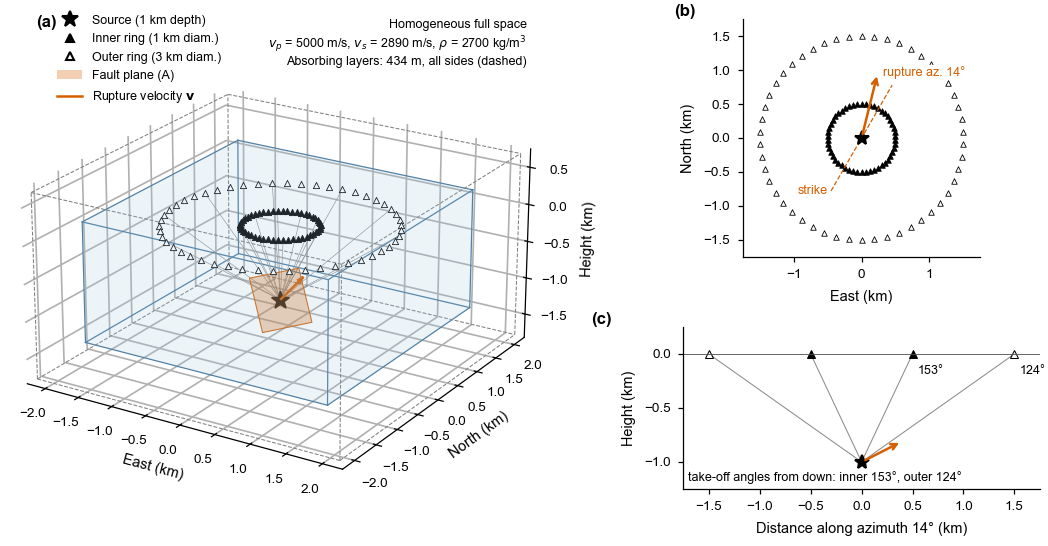

In [3]:
# Simulation volume (also used by the Salvus cell) and absorbing layers
domain_dict = {'x0': -1750.0, 'x1': 1750.0, 'y0': -1750.0, 'y1': 1750.0, 'z0': -1350.0, 'z1': 250.0}
ABS_REF_FREQ, ABS_N_WAVELENGTHS = 10.0, 1.5      # absorbing layer: 1.5 wavelengths of vs at 10 Hz
abs_width = ABS_N_WAVELENGTHS * vs / ABS_REF_FREQ

# Fault plane and rupture velocity vector of the true sources (defined fully in section 6):
STRIKE, DIP, RAKE = 30.0, 60.0, -60.0
s_hat = np.array([np.sin(np.radians(STRIKE)), np.cos(np.radians(STRIKE)), 0.0])          # along strike (ENU)
dip_az = np.radians(STRIKE + 90.0)
dip_hat = np.array([np.cos(np.radians(DIP)) * np.sin(dip_az), np.cos(np.radians(DIP)) * np.cos(dip_az),
                    -np.sin(np.radians(DIP))])                                            # down dip (ENU)
RUPT_ANGLE = 30.0                                # rupture direction: 30 deg up-dip from along-strike, in the fault plane
d_hat = np.cos(np.radians(RUPT_ANGLE)) * s_hat - np.sin(np.radians(RUPT_ANGLE)) * dip_hat
V_REL = 0.7                                      # |v| / vs
v_true = V_REL * vs * d_hat
vr_t, az_t, pl_t = spectra.rupture_from_vector(v_true)
az_t, pl_t = np.degrees(az_t), np.degrees(pl_t)
print(f"v_true = {np.round(v_true)} m/s: |v| = {vr_t:.0f} m/s = {V_REL} vs, azimuth {az_t:.1f} deg, "
      f"plunge {pl_t:.1f} deg (negative = upward)")


def box_faces(x0, x1, y0, y1, z0, z1):
    X = [[x0, y0, z0], [x1, y0, z0], [x1, y1, z0], [x0, y1, z0], [x0, y0, z1], [x1, y0, z1], [x1, y1, z1], [x0, y1, z1]]
    idx = [[0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4], [2, 3, 7, 6], [1, 2, 6, 5], [0, 3, 7, 4]]
    return [[X[i] for i in f] for f in idx]


def box_edges(ax, b, **kw):
    x0, x1, y0, y1, z0, z1 = b
    for xs, ys, zs in (([x0, x1], [y0, y0], [z0, z0]), ([x0, x1], [y1, y1], [z0, z0]), ([x0, x1], [y0, y0], [z1, z1]),
                       ([x0, x1], [y1, y1], [z1, z1]), ([x0, x0], [y0, y1], [z0, z0]), ([x1, x1], [y0, y1], [z0, z0]),
                       ([x0, x0], [y0, y1], [z1, z1]), ([x1, x1], [y0, y1], [z1, z1]), ([x0, x0], [y0, y0], [z0, z1]),
                       ([x1, x1], [y0, y0], [z0, z1]), ([x0, x0], [y1, y1], [z0, z1]), ([x1, x1], [y1, y1], [z0, z1])):
        ax.plot(xs, ys, zs, **kw)


from mpl_toolkits.mplot3d.art3d import Poly3DCollection

km = 1e-3
zs = lambda z: (np.asarray(z) - Z_REC) * km      # plot heights relative to the receiver plane (km)
fig = plt.figure(figsize=(W2, 3.6))
ax = fig.add_axes([-0.04, 0.0, 0.64, 1.0], projection='3d')
d = domain_dict
b_dom = (d['x0'] * km, d['x1'] * km, d['y0'] * km, d['y1'] * km, zs(d['z0']), zs(d['z1']))
b_abs = (b_dom[0] - abs_width * km, b_dom[1] + abs_width * km, b_dom[2] - abs_width * km, b_dom[3] + abs_width * km,
         b_dom[4] - abs_width * km, b_dom[5] + abs_width * km)
ax.add_collection3d(Poly3DCollection(box_faces(*b_dom), facecolor='#9ecae1', edgecolor='none', alpha=0.10))
box_edges(ax, b_dom, color='#4a7aa0', lw=0.6)
box_edges(ax, b_abs, color='0.5', lw=0.5, ls='--')
# Receivers and rays
for k, (mk, fc) in enumerate((('^', 'k'), ('^', 'w'))):
    s = ring == k
    ax.scatter(rec_xyz[s, 0] * km, rec_xyz[s, 1] * km, zs(rec_xyz[s, 2]), marker=mk, s=9, facecolor=fc,
               edgecolor='k', linewidth=0.4, depthshade=False)
for i in np.flatnonzero(np.isin(np.arange(n_per_ring), np.arange(0, n_per_ring, 5))):
    for j in (i, i + n_per_ring):
        ax.plot([src_xyz[0] * km, rec_xyz[j, 0] * km], [src_xyz[1] * km, rec_xyz[j, 1] * km],
                [zs(src_xyz[2]), zs(rec_xyz[j, 2])], color='0.55', lw=0.3)
# Fault plane (source A's DC part), source and rupture vector
L = 0.35
corners = np.array([src_xyz * km + L * (a * s_hat + b * dip_hat) for a, b in ((-1, -1), (1, -1), (1, 1), (-1, 1))])
corners[:, 2] = zs(corners[:, 2] / km)
ax.add_collection3d(Poly3DCollection([corners], facecolor='#D55E00', edgecolor='#D55E00', alpha=0.30, lw=0.5))
ax.scatter(*src_xyz[:2] * km, zs(src_xyz[2]), marker='*', s=70, color='k', depthshade=False, zorder=10)
ax.quiver(*src_xyz[:2] * km, zs(src_xyz[2]), *(0.45 * d_hat), color='#D55E00', lw=1.2, arrow_length_ratio=0.25)
ax.set(xlabel='East (km)', ylabel='North (km)', zlabel='Height (km)',
       xlim=b_abs[:2], ylim=b_abs[2:4], zlim=b_abs[4:])
ax.set_box_aspect((b_abs[1] - b_abs[0], b_abs[3] - b_abs[2], b_abs[5] - b_abs[4]))
ax.view_init(elev=22, azim=-58)
ax.tick_params(pad=0)
for a in (ax.xaxis, ax.yaxis, ax.zaxis):
    a.labelpad = -4
    a.pane.set_alpha(0.0)
ax.text2D(0.97, 0.97, f'Homogeneous full space\n$v_p$ = {vp:.0f} m/s, $v_s$ = {vs:.0f} m/s, $\\rho$ = {rho:.0f} kg/m$^3$\n'
          f'Absorbing layers: {abs_width:.0f} m, all sides (dashed)', transform=ax.transAxes, fontsize=6,
          ha='right', va='top')
ax.legend(handles=[Line2D([], [], marker='*', ls='', color='k', ms=8, label='Source (1 km depth)'),
                   Line2D([], [], marker='^', ls='', mfc='k', mec='k', ms=4, label='Inner ring (1 km diam.)'),
                   Line2D([], [], marker='^', ls='', mfc='w', mec='k', ms=4, label='Outer ring (3 km diam.)'),
                   Patch(facecolor='#D55E00', alpha=0.3, label='Fault plane (A)'),
                   Line2D([], [], color='#D55E00', lw=1.2, label='Rupture velocity $\\mathbf{v}$')],
          loc='upper left', bbox_to_anchor=(0.08, 1.0), fontsize=6)

# (b) Map view
ax2 = fig.add_axes([0.66, 0.53, 0.33, 0.44])
for k, (fc, lab) in enumerate((('k', 'inner'), ('w', 'outer'))):
    s = ring == k
    ax2.scatter(rec_xyz[s, 0] * km, rec_xyz[s, 1] * km, marker='^', s=7, facecolor=fc, edgecolor='k', lw=0.4)
tr = np.array([-1, 1])[:, None] * 0.9 * s_hat[None, :2]
ax2.plot(tr[:, 0], tr[:, 1], color='#D55E00', lw=0.6, ls='--')
ax2.text(tr[0, 0] - 0.05, tr[0, 1], 'strike', color='#D55E00', fontsize=6, ha='right', va='center')
ax2.plot(0, 0, '*', color='k', ms=7)
ax2.annotate('', xy=(1.0 * np.sin(np.radians(az_t)), 1.0 * np.cos(np.radians(az_t))), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color='#D55E00', lw=1.2))
ax2.text(1.0 * np.sin(np.radians(az_t)) + 0.08, 1.0 * np.cos(np.radians(az_t)), f'rupture az. {az_t:.0f}°',
         color='#D55E00', fontsize=6, va='center', bbox=dict(facecolor='w', edgecolor='none', pad=0.5))
ax2.set(xlabel='East (km)', ylabel='North (km)', aspect='equal', xlim=(-1.75, 1.75), ylim=(-1.75, 1.75))

# (c) Vertical section along the rupture azimuth
ax3 = fig.add_axes([0.66, 0.1, 0.33, 0.3])
for k, (fc, rr) in enumerate((('k', RING_RADII[0]), ('w', RING_RADII[1]))):
    for sgn in (-1, 1):
        ax3.plot([0, sgn * rr * km], [-DEPTH * km, 0], color='0.55', lw=0.5)
        ax3.plot(sgn * rr * km, 0, '^', mfc=fc, mec='k', ms=4, mew=0.5)
    ax3.text(rr * km + 0.05, -0.1, f'{180 - np.degrees(np.arctan2(rr, DEPTH)):.0f}°', fontsize=6, ha='left', va='top')
ax3.plot(0, -DEPTH * km, '*', color='k', ms=7)
h = np.hypot(*d_hat[:2])
ax3.annotate('', xy=(0.45 * h, -DEPTH * km - 0.45 * d_hat[2] * -1), xytext=(0, -DEPTH * km),
             arrowprops=dict(arrowstyle='->', color='#D55E00', lw=1.2))
ax3.axhline(0, color='0.3', lw=0.4)
ax3.set(xlabel=f'Distance along azimuth {az_t:.0f}° (km)', ylabel='Height (km)', xlim=(-1.75, 1.75), ylim=(-1.25, 0.25))
ax3.text(-1.7, -1.2, 'take-off angles from down: inner 153°, outer 124°', fontsize=6, va='bottom')
label_panels([ax], x=0.1, y=0.95)
label_panels([ax2, ax3], start=1, x=-0.2, y=1.0)
savefig(fig, 'fig01_model_setup')

## 5. Green's functions

### 5.1 Salvus simulations (optional: `GF_SOURCE = 'salvus'`; run once, cached)
- **Medium:** homogeneous rock (above) with high Q, in a full space. `gen_body_waves_only=True` turns off the free surface, so the boundaries absorb on all sides.
- **Wavelet:** `FlatSpectrumWavelet(0.5, 1, 23, 25 Hz)`. Salvus truncates it to ±0.2/f0 = ±0.4 s, hence the 0.4 s time shift.
- **Mesh:** 25 Hz maximum frequency, 2 elements per minimum wavelength, tensor order 2.
- **Absorbing layers:** 1.5 wavelengths of $v_s$ at 10 Hz (about 430 m). This needs the driver arguments `absorbing_reference_velocity` and `absorbing_number_of_wavelengths`.
- **Output:** receiver velocity only (`volume_output=False`), at 100 Hz.
- **Run time.** The local Salvus site runs the six jobs one after another, each on `ranks_per_job=8` MPI ranks (the site maximum). The driver keeps macOS awake while they run. The domain margins and the absorbing-layer width set the cost. If the runs are too slow, reduce the margins first, while keeping boundary reflections out of the window; the check in 5.3 shows them.
- **Caching.** The run is skipped if the synthetics already exist in `SYNTH_DIR`.

Driver conventions (`unshake.salvus_fwd_driver.gen_synths_salvus`):
- coordinates are passed in metres / 1e6;
- in full space it moves receivers 10 m down, so the receivers are passed at z = 0 and the source at z = −1010 m;
- receiver names must not start with `D` (the DAS projection).

In [4]:
END_TIME = 0.4 + T_WIN + 0.32                    # wavelet shift + window + margin (s)
RUN_FWD = GF_SOURCE == 'salvus' and not glob.glob(str(SYNTH_DIR / '*.m'))
print('RUN_FWD =', RUN_FWD)
if RUN_FWD:
    import salvus.namespace as sn
    from unshake.salvus_fwd_driver import gen_synths_salvus

    wavelet = sn.simple_config.stf.FlatSpectrumWavelet(f0=0.5, f1=1.0, f2=23.0, f3=F_MAX, time_shift_in_seconds=0.4)
    receivers_df = pd.DataFrame({'Name': rec_names, 'x_m': rec_xyz[:, 0] / 1e6, 'y_m': rec_xyz[:, 1] / 1e6,
                                 'z_m': np.zeros(n_rec)})          # driver puts full-space receivers at z = -10 m
    x = y = np.linspace(-3500.0, 3500.0, 15)                       # model grid covers domain + absorbing layers
    z = np.linspace(-3000.0, 2000.0, 11)
    shape = (len(x), len(y), len(z))
    medium_model_dict = {'vp': np.full(shape, vp), 'vs': np.full(shape, vs), 'rho': np.full(shape, rho),
                         'qkappa': np.full(shape, 2 * Q_mu), 'qmu': np.full(shape, Q_mu), 'x': x, 'y': y, 'z': z}
    out_settings = {'output_fs_Hz': int(fs), 'gaussian_noise_dur_s': 0, 'snr_amp': 100.0,
                    'add_noise_to_signal': False, 'wfs_outdir': str(SYNTH_DIR)}
    tic = time.time()
    gen_synths_salvus(PROJECT_PATH, domain_dict, src_xyz / 1e6, receivers_df, medium_model_dict,
                      centre_freq_Hz=ABS_REF_FREQ,           # = absorbing-layer reference frequency here
                      output_waveforms_settings_dict=out_settings, gen_body_waves_only=True,
                      end_time_in_seconds=END_TIME, wavelet=wavelet, max_frequency_in_hertz=F_MAX,
                      elements_per_wavelength=2.0, absorbing_reference_velocity=vs,
                      absorbing_number_of_wavelengths=ABS_N_WAVELENGTHS, volume_output=False,
                      ranks_per_job=8)                      # 8 = local site max_ranks
    print(f"Salvus run time (6 MT components): {time.time() - tic:.0f} s")
    t_rate, rate = wavelet.get_stf_rate()                          # keep the wavelet: later runs need no Salvus
    np.savez(OUT / 'wavelet_rate.npz', t=t_rate - wavelet.get_auto_start_time(), rate=rate)

RUN_FWD = False


### 5.2 Analytic full-space Green's functions
- **Solution.** For a homogeneous, isotropic full space, the displacement from a moment tensor source is known in closed form (Aki & Richards 2002, eq. 4.29). It has near-field ($r^{-4}$), intermediate-field ($r^{-2}$) and far-field ($r^{-1}$) P and S terms.
- **Formal GFs.** Setting the moment rate to a unit impulse and evaluating each term in the frequency domain (times $B$) gives the formal band-limited velocity GFs directly. They are in the same Salvus component order, so they share the processing below.
- **Uses:** the default GFs of this notebook (`GF_SOURCE = 'analytic'`), and a check of the Salvus GFs (section 5.3). Attenuation ($Q_\mu$ = 1000) is negligible over these distances, so it is ignored.

In [5]:
def fullspace_gf_enu(rec_xyz, src_xyz, vp, vs, rho, dt, n_t, band, nfft=8192):
    """Formal band-limited velocity GFs of a homogeneous full space (Aki & Richards 2002, eq. 4.29).

    Velocity (ENU receiver components) for a unit-impulse moment rate of each Salvus MT component
    [Mxx, Myy, Mzz, Mxy, Mxz, Myz] (x = E, y = N, z = U), filtered by B = flat_band(f, *band).
    Returns (n_rec, 3, 6, n_t), sample 0 = origin time.
    """
    f = np.fft.rfftfreq(nfft, dt)
    w = 2.0 * np.pi * f
    wz = np.where(w > 0, w, 1.0)
    B = spectra.flat_band(f, *band)
    unit = []
    for p, q in [(0, 0), (1, 1), (2, 2), (0, 1), (0, 2), (1, 2)]:
        E = np.zeros((3, 3))
        E[p, q] = E[q, p] = 1.0
        unit.append(E)
    I3 = np.eye(3)
    out = np.zeros((len(rec_xyz), 3, 6, n_t))
    for i, x in enumerate(rec_xyz):
        rv = x - src_xyz
        r = np.linalg.norm(rv)
        g = rv / r
        ta, tb = r / vp, r / vs
        F = lambda t: np.exp(-1j * wz * t) * (1j * t / wz + 1.0 / wz ** 2)  # FT of t on [ta, tb] (near field)
        NF = np.where(w > 0, F(tb) - F(ta), 0.0)
        Pa, Pb = np.exp(-1j * w * ta), np.exp(-1j * w * tb)
        for n in range(3):
            ggg = np.outer(g, g) * g[n]
            K_nf = 15 * ggg - 3 * g[n] * I3 - 3 * np.outer(I3[n], g) - 3 * np.outer(g, I3[n])
            K_ip = 6 * ggg - g[n] * I3 - np.outer(I3[n], g) - np.outer(g, I3[n])
            K_is = 6 * ggg - g[n] * I3 - np.outer(I3[n], g) - 2 * np.outer(g, I3[n])
            K_fs = np.outer(g[n] * g, g) - np.outer(I3[n], g)
            for k, E in enumerate(unit):
                c = [np.sum(E * K) for K in (K_nf, K_ip, K_is, ggg, K_fs)]
                U = (c[0] / r ** 4 * NF + c[1] / (vp ** 2 * r ** 2) * Pa - c[2] / (vs ** 2 * r ** 2) * Pb
                     + c[3] / (vp ** 3 * r) * 1j * w * Pa - c[4] / (vs ** 3 * r) * 1j * w * Pb) / (4 * np.pi * rho)
                out[i, n, k] = np.fft.irfft(U * B, n=nfft)[:n_t] / dt
    return out


NED_IDX, NED_SIGN = [1, 0, 2, 3, 5, 4], np.array([1., 1., 1., 1., -1., -1.])   # Salvus ENU -> NED MT components
phi = np.radians(rec_az)
COMP_DIRS = {'Z': np.tile([0., 0., 1.], (n_rec, 1)),
             'R': np.column_stack([np.sin(phi), np.cos(phi), np.zeros(n_rec)]),
             'T': np.column_stack([np.cos(phi), -np.sin(phi), np.zeros(n_rec)])}


def gf_dataset(gf_enu, meta):
    """Formal GFs (n_rec, 3 ENU, 6 Salvus MT comps, n_t) -> Dataset with NED MT columns, traces ordered
    [Z (inner, outer), R (...), T (...)], data = 0, windowed to [0, T_WIN)."""
    gf_ned = gf_enu[:, :, NED_IDX] * NED_SIGN[None, None, :, None]
    labels, coords, chans, gfs = [], [], [], []
    for c, dirs in COMP_DIRS.items():
        for i in range(n_rec):
            labels.append(f"{rec_names[i]}{c}")
            coords.append(rec_xyz[i])
            chans.append(dirs[i])
            gfs.append(np.einsum('k,kjt->jt', dirs[i], gf_ned[i]))
    gf = np.array(gfs)
    return unshake.Dataset(data=np.zeros((gf.shape[0], gf.shape[-1])), gf={'mt': gf}, dt=dt,
                           receivers=unshake.Receivers(labels=labels, coords=coords, channel_dirs=chans,
                                                       phase='P', velocity=vp),
                           source=unshake.Source(uid='paper_synthetic', coords=src_xyz), t0=0.0,
                           meta=dict(meta, gf_band=band, data_band=band)).window(0.0, T_WIN)


n_t_full = int(round(T_WIN * fs)) + 64
ds_an = gf_dataset(fullspace_gf_enu(rec_xyz, src_xyz, vp, vs, rho, dt, n_t_full, band),
                   {'gf': 'analytic homogeneous full space (Aki & Richards eq. 4.29), formal band-limited'})
if GF_SOURCE == 'salvus':
    import obspy
    w = np.load(OUT / 'wavelet_rate.npz')
    gf_raw = None
    for j, Mc in enumerate(['Mxx', 'Myy', 'Mzz', 'Mxy', 'Mxz', 'Myz']):
        for k, ch in enumerate(['HHE', 'HHN', 'HHZ']):
            for i, name in enumerate(rec_names):
                tr = obspy.read(str(SYNTH_DIR / f"2000001_{name}_{ch}_{Mc}.m"))[0]
                if gf_raw is None:
                    gf_raw = np.zeros((n_rec, 3, 6, tr.stats.npts))
                gf_raw[i, k, j] = tr.data[:gf_raw.shape[-1]]
    # Divide out the wavelet's moment rate and apply B (traces start at the origin time):
    ds_gf = gf_dataset(forward.remove_stf(gf_raw, dt, (w['t'], w['rate']), band),
                       {'gf': 'Salvus full space, homogeneous rock, FlatSpectrumWavelet(0.5, 1, 23, 25); '
                              'moment-rate STF removed -> formal band-limited GF'})
else:
    ds_gf = ds_an
ds_gf.save(GF_PATH)
ds_gf.check_band()
print(ds_gf)
G = ds_gf.gf['mt']
COMP = np.repeat(np.array(list('ZRT')), n_rec)      # component of each trace
REC = np.tile(np.arange(n_rec), 3)                   # receiver index of each trace

Note: GFs and data must be band-limited by the same filter B: gf_band=(1.0, 2.0, 20.0, 23.0), data_band=(1.0, 2.0, 20.0, 23.0)
Dataset(uid='paper_synthetic', n_rec=300, n_t=128, dt=0.01, gf=[mt(300, 6, 128)])


### 5.3 Check: Salvus vs analytic Green's functions
The figure shows the GFs times the MT of source A (no STF) at an inner-ring and an outer-ring receiver, from Salvus and from the analytic solution. The relative L2 misfit $\|g_{\rm Salvus} - g_{\rm analytic}\|/\|g_{\rm analytic}\|$ is then given over all traces, per ring and component.

Expected sources of difference:
- the coarse mesh (2 elements per wavelength, tensor order 2) near 25 Hz;
- weak absorbing-boundary reflections;
- $Q$.

With `GF_SOURCE = 'analytic'`, the check is trivial (zero misfit), and only the analytic GFs are plotted.

Relative L2 misfit, Salvus vs analytic GFs (x MT of source A):


,Z,R,T
inner ring,0.0,0.0,0.0
outer ring,0.0,0.0,0.0


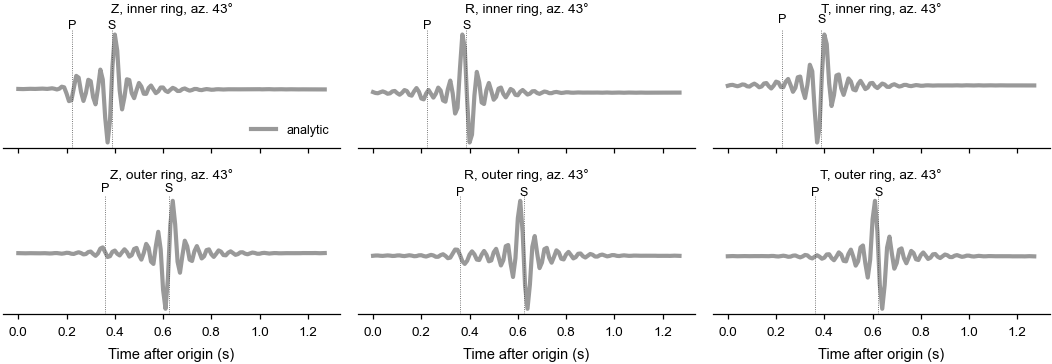

In [6]:
_, V_axes = mt.eig(mt.from_sdr(STRIKE, DIP, RAKE))
m_check = mt.normalise(mt.from_33(V_axes @ np.diag([1.0, 0.15, -0.8]) @ V_axes.T))   # source A's MT
g_s, g_a = forward.synthetics(ds_gf.gf['mt'], m_check), forward.synthetics(ds_an.gf['mt'], m_check)
rel = pd.DataFrame({c: [np.linalg.norm(g_s[(COMP == c) & (ring[REC] == k)] - g_a[(COMP == c) & (ring[REC] == k)])
                        / np.linalg.norm(g_a[(COMP == c) & (ring[REC] == k)]) for k in (0, 1)]
                    for c in 'ZRT'}, index=['inner ring', 'outer ring'])
print('Relative L2 misfit, Salvus vs analytic GFs (x MT of source A):')
display(rel.round(3))

fig, axes = plt.subplots(2, 3, figsize=(W2, 2.6), sharex=True)
t = ds_gf.times
for row, i_rec in enumerate((6, n_per_ring + 6)):
    for col, c in enumerate('ZRT'):
        ax = axes[row, col]
        tr = np.flatnonzero((COMP == c) & (REC == i_rec))[0]
        sc = np.abs(g_a[tr]).max()
        ax.plot(t, g_a[tr] / sc, color='0.6', lw=2.0, label='analytic')
        if GF_SOURCE == 'salvus':
            ax.plot(t, g_s[tr] / sc, color='k', lw=0.7, label='Salvus')
            ax.plot(t, (g_s[tr] - g_a[tr]) / sc - 1.6, color='#CC79A7', lw=0.7, label='difference')
        for tt, ph in ((dist[i_rec] / vp, 'P'), (dist[i_rec] / vs, 'S')):
            ax.axvline(tt, color='0.3', lw=0.4, ls=':')
            ax.text(tt, 1.05, ph, fontsize=6, ha='center', va='bottom')
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)
        ax.set_title(f"{c}, {('inner', 'outer')[row]} ring, az. {rec_az[i_rec]:.0f}°", fontsize=6.5, pad=8)
for ax in axes[-1]:
    ax.set_xlabel('Time after origin (s)')
axes[0, 0].legend(loc='lower right', fontsize=6)
fig.tight_layout()
savefig(fig, 'figS1_gf_check')

## 6. True sources and synthetic data

All three sources share:
- the corner frequency $f_{c0}$ = 6 Hz;
- the rupture velocity vector: $|\mathbf{v}| = 0.7\,v_s$, in the fault plane of the DC part (strike 30°, dip 60°), pointing 30° up-dip from horizontal along strike. That is azimuth ≈ 14°, plunge ≈ −26° (upward), so the true $v_U$ is not zero.

| | Moment tensor | DC-part STF |
|---|---|---|
| **A** | DC-dominant: eigenvalues (1, 0.15, −0.8) on the principal axes of DC (30°, 60°, −60°) | unilateral, $\mathbf{v}$ |
| **B** | tensile-dominant: 75 % tensile crack (3 : 1 : 1, opening along the T axis) + 25 % DC on the same axes (Frobenius-norm weights) | unilateral, $\mathbf{v}$ |
| **C** | as A | bilateral: halves at $\pm\mathbf{v}$, each with corner $2f_{c0}$ (section 1.4) |

- **Amplitude.** Every MT has unit Frobenius norm. Amplitudes are relative, since the noise is scaled to the data.
- **Noise.** Gaussian noise, band-limited by $B$, at peak SNR 20, with a fixed random seed per source.

In [7]:
mA = mt.normalise(mt.from_33(V_axes @ np.diag([1.0, 0.15, -0.8]) @ V_axes.T))
crack = V_axes @ np.diag([3.0, 1.0, 1.0]) @ V_axes.T
dc33 = V_axes @ np.diag([1.0, 0.0, -1.0]) @ V_axes.T
mB = mt.normalise(mt.from_33(0.75 * crack / np.linalg.norm(crack) + 0.25 * dc33 / np.linalg.norm(dc33)))


def forward_bilateral(p, ds):
    """True forward model of source C: the DC part ruptures bilaterally (two halves of the same total length,
    each of half the moment, with corner 2 fc0 and Doppler +v and -v); the non-DC part has S(f; fc0)."""
    p = np.atleast_2d(p)
    _, _, _, m_dc, m_ndc = mt.decompose(p[:, :6])
    fc_p = spectra.apparent_fc_vector(2 * p[:, 6], p[:, 7:10], ds.receivers.velocity, ds.ray_dirs)[..., None]
    fc_m = spectra.apparent_fc_vector(2 * p[:, 6], -p[:, 7:10], ds.receivers.velocity, ds.ray_dirs)[..., None]
    s_bi = lambda f: 0.5 * (stfs.brune_stf_spectrum(f, fc_p) + stfs.brune_stf_spectrum(f, fc_m))
    return (forward.convolve_stf(forward.synthetics(ds.gf['mt'], m_dc), ds.dt, s_bi)
            + forward.convolve_stf(forward.synthetics(ds.gf['mt'], m_ndc), ds.dt,
                                   lambda f: stfs.brune_stf_spectrum(f, p[:, 6, None, None])))


def add_noise(d, rng):
    n = forward.bandlimit(rng.standard_normal(d.shape), dt, band)
    return d + n * (np.abs(d).max() / SNR) / n.std()


true_model = unshake.MTDCDirectivityModel(scale=1.0)
SOURCES = {
    'A': dict(title='A: DC-dominant, unilateral', m=mA, forward=true_model.forward, seed=11),
    'B': dict(title='B: tensile-dominant, unilateral', m=mB, forward=true_model.forward, seed=12),
    'C': dict(title='C: DC-dominant, bilateral', m=mA, forward=forward_bilateral, seed=13),
}
rows = {}
for key, S in SOURCES.items():
    S['p_true'] = np.r_[S['m'], FC0_TRUE, v_true]
    S['d_clean'] = S['forward'](S['p_true'], ds_gf)[0]
    S['ds'] = unshake.Dataset(data=add_noise(S['d_clean'], np.random.default_rng(S['seed'])), gf=ds_gf.gf, dt=dt,
                              receivers=ds_gf.receivers, source=ds_gf.source, meta=dict(ds_gf.meta))
    c_iso, c_clvd, c_dc, m_dc, _ = mt.decompose(S['m'])
    g, de = np.degrees(mt.lune(S['m']))
    rows[S['title']] = {'ISO (%)': 100 * c_iso, 'CLVD (%)': 100 * c_clvd, 'DC (%)': 100 * c_dc,
                        'lune gamma (deg)': g, 'lune delta (deg)': de,
                        'DC strike/dip/rake': np.round(mt.sdr(m_dc)[1]).astype(int).tolist(),
                        'fc0 (Hz)': FC0_TRUE, '|v|/vs': V_REL, 'v azimuth (deg)': az_t, 'v plunge (deg)': pl_t,
                        'VR of true model': float(misfit.vr(S['ds'].data, S['d_clean']))}
tab_sources = pd.DataFrame(rows).T
tab_sources.to_csv(FIG_DIR / 'table_sources.csv')
display(tab_sources.round(2))

,ISO (%),CLVD (%),DC (%),lune gamma (deg),lune delta (deg),DC strike/dip/rake,fc0 (Hz),|v|/vs,v azimuth (deg),v plunge (deg),VR of true model
"A: DC-dominant, unilateral",11.290323,-6.451613,82.258065,1.837133,9.01661,"[30, 60, -60]",6.0,0.7,13.897886,-25.658906,0.579373
"B: tensile-dominant, unilateral",44.071471,35.257177,20.671352,-17.954298,47.46203,"[30, 60, -60]",6.0,0.7,13.897886,-25.658906,0.576469
"C: DC-dominant, bilateral",11.290323,-6.451613,82.258065,1.837133,9.01661,"[30, 60, -60]",6.0,0.7,13.897886,-25.658906,0.594828


### 6.1 True sources: moment tensors and DC-part source time functions
- **Top row:** beachballs of the three true sources (lower hemisphere) and their lune positions.
- **Bottom row:** moment-rate functions of the DC part towards (forward) and away from (backward) the rupture, for the unilateral (A, B) and bilateral (C) sources, at both rings, together with the direction-independent non-DC STF.

The bilateral STF is shorter, since each half is half as long, and it is almost the same in the forward and backward directions.

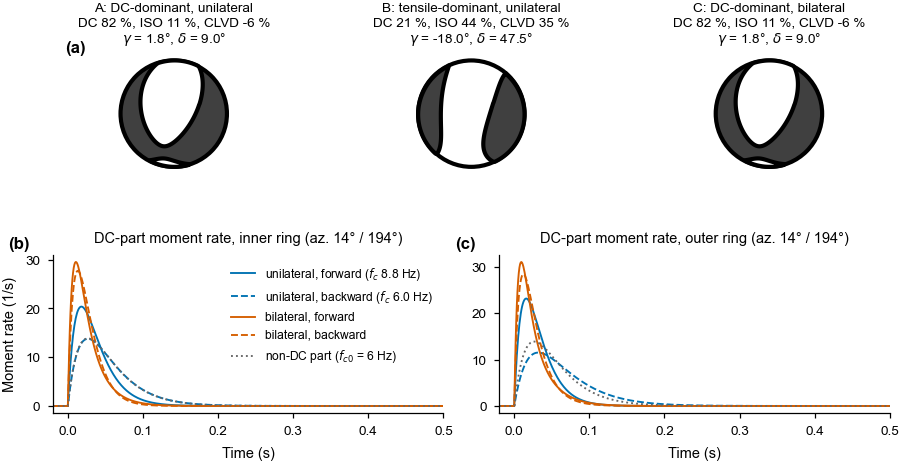

In [8]:
fwd_i = [int(np.argmin(np.abs(((rec_az - az_t + 180) % 360) - 180) + 1e3 * (ring != k))) for k in (0, 1)]
bwd_i = [int(np.argmin(np.abs(((rec_az - az_t) % 360) - 180) + 1e3 * (ring != k))) for k in (0, 1)]
fc2 = true_model.corner_frequencies(SOURCES['A']['p_true'], ds_gf)[0]          # (n_traces,)
fcp = spectra.apparent_fc_vector(2 * FC0_TRUE, v_true, vp, ds_gf.ray_dirs)[0]
fcm = spectra.apparent_fc_vector(2 * FC0_TRUE, -v_true, vp, ds_gf.ray_dirs)[0]
tt = np.linspace(-0.02, 0.5, 600)

fig = plt.figure(figsize=(W2, 3.1))
gs = fig.add_gridspec(2, 6, height_ratios=[0.85, 1.15], hspace=0.6, wspace=0.6)
for col, key in enumerate('ABC'):
    S = SOURCES[key]
    ax = fig.add_subplot(gs[0, 2 * col:2 * col + 2])
    plot.beachball(S['m'], ax=ax, facecolor='0.25')
    c_iso, c_clvd, c_dc = mt.decompose(S['m'])[:3]
    g, de = np.degrees(mt.lune(S['m']))
    ax.set_title(f"{S['title']}\nDC {100 * c_dc:.0f} %, ISO {100 * c_iso:.0f} %, CLVD {100 * c_clvd:.0f} %"
                 f"\n$\\gamma$ = {g:.1f}°, $\\delta$ = {de:.1f}°", fontsize=6.5)
    if col == 0:
        label_panels([ax], x=-0.25, y=1.0)
axes = [fig.add_subplot(gs[1, 0:3]), fig.add_subplot(gs[1, 3:6])]
for ax, k in zip(axes, (0, 1)):
    trf, trb = fwd_i[k], bwd_i[k]                   # Z traces: same index as the receiver
    ax.plot(tt, stfs.brune_stf(tt, fc2[trf]), color='#0072B2', label=f'unilateral, forward ($f_c$ {fc2[trf]:.1f} Hz)')
    ax.plot(tt, stfs.brune_stf(tt, fc2[trb]), color='#0072B2', ls='--', label=f'unilateral, backward ($f_c$ {fc2[trb]:.1f} Hz)')
    ax.plot(tt, 0.5 * (stfs.brune_stf(tt, fcp[trf]) + stfs.brune_stf(tt, fcm[trf])), color='#D55E00',
            label='bilateral, forward')
    ax.plot(tt, 0.5 * (stfs.brune_stf(tt, fcp[trb]) + stfs.brune_stf(tt, fcm[trb])), color='#D55E00', ls='--',
            label='bilateral, backward')
    ax.plot(tt, stfs.brune_stf(tt, FC0_TRUE), color='0.4', ls=':', label=f'non-DC part ($f_{{c0}}$ = {FC0_TRUE:g} Hz)')
    ax.set(xlabel='Time (s)', title=f"DC-part moment rate, {('inner', 'outer')[k]} ring "
                                    f"(az. {rec_az[trf]:.0f}° / {rec_az[trb]:.0f}°)", xlim=(tt[0], tt[-1]))
    ax.set_ylabel('Moment rate (1/s)' if k == 0 else '')
axes[0].legend(fontsize=5.8, loc='upper right')
label_panels(axes, start=1, x=-0.06, y=1.02)
savefig(fig, 'fig02_true_sources')

## 7. Inversions

**Settings** (the same for every source):
- `MTDCDirectivityModel(fc0_range=(1, 30) Hz, sigma_v=0.5 vs, v_max=0.9 vs)`.
- **MC:** 20 000 prior samples, in batches of 100 (larger batches are memory-bound and much slower).
- **NLLS:** 1 + 4 starts.
- **MCMC:** 8 chains × 4000 steps, burn-in 2000, so 16 000 posterior samples.
- **NLLS Gaussian:** 20 000 draws from $\mathcal{N}(\hat{\mathbf{p}}, \mathbf{C})$, for plots of derived quantities and the lune.

**Caching.** Results are cached in `INV_PATH`. Delete that file after changing the data or the settings.

In [9]:
KW = dict(fc0_range=(1.0, 30.0), sigma_v=0.5 * vs, v_max=0.9 * vs)
N_MC, N_STEPS, N_CHAINS, N_DRAWS = 20_000, 4000, 8, 20_000
PARAM_NAMES = unshake.MTDCDirectivityModel().param_names
INV = pickle.load(open(INV_PATH, 'rb')) if INV_PATH.exists() else {}


def invert(key):
    """Starting model, MC, NLLS and MCMC for source `key`; returns a dict of results and timings."""
    ds = SOURCES[key]['ds']
    out = {}
    tic = time.time()
    out['p0'] = unshake.MTDCDirectivityModel(**KW).find_non_linear_starting_model_params(ds)
    out['t_start'] = time.time() - tic
    tic = time.time()
    out['mc'] = unshake.monte_carlo(unshake.MTDCDirectivityModel(**KW), ds, N_MC, batch=100, rng=1)
    out['t_mc'] = time.time() - tic
    model = unshake.MTDCDirectivityModel(**KW)
    tic = time.time()
    p_hat, cov, info = unshake.nonlinear_least_squares(model, ds, rng=1)
    out['t_nlls'] = time.time() - tic
    tic = time.time()
    out['mcmc'] = unshake.mcmc(model, ds, p_hat, cov, n_steps=N_STEPS, n_chains=N_CHAINS, sigma=info['sigma'], rng=3)
    out['t_mcmc'] = time.time() - tic
    out.update(p_hat=p_hat, cov=cov, info={k: v for k, v in info.items() if k != 'result'}, scale=model.scale,
               draws=np.random.default_rng(2).multivariate_normal(p_hat, cov, N_DRAWS))
    return out


def run_or_load(key):
    if key not in INV:
        INV[key] = invert(key)
        with open(INV_PATH, 'wb') as f:
            pickle.dump(INV, f)
    else:
        print(f'source {key}: loaded cached inversion results from {INV_PATH}')
    return INV[key]


def best_models(key):
    R = INV[key]
    return {'start': R['p0'], 'MC': R['mc'].best, 'NLLS': R['p_hat'], 'MCMC': R['mcmc'].best}


def summary_table(key):
    """True vs best / mean +- sd for each parameter, and the MCMC diagnostics."""
    R, S = INV[key], SOURCES[key]
    sd = np.sqrt(np.diag(R['cov']))
    post = R['mcmc'].params
    df = pd.DataFrame({'true': S['p_true'], 'start': R['p0'], 'MC best': R['mc'].best, 'NLLS': R['p_hat'],
                       'NLLS sd (GN)': sd, 'MCMC mean': post.mean(0), 'MCMC sd': post.std(0),
                       'R-hat': R['mcmc'].meta['rhat'], 'tau (steps)': R['mcmc'].meta['tau']}, index=PARAM_NAMES)
    m = R['mcmc'].meta
    print(f"{S['title']}: times start {R['t_start']:.1f} s, MC {R['t_mc']:.1f} s (ESS {R['mc'].ess:.1f}), "
          f"NLLS {R['t_nlls']:.1f} s ({R['info']['nfev']} forward evals), MCMC {R['t_mcmc']:.1f} s; "
          f"MCMC acceptance {m['acceptance']:.2f}, max R-hat {np.nanmax(m['rhat']):.3f}, ESS {m['ess']:.0f}")
    return df

### 7.1 Plotting helpers
These functions are shared by all sources and figures:
- derived quantities;
- samples from the MCMC prior;
- 68/95 % highest-posterior-density (HPD) contours;
- the Kagan angle;
- the three per-source figures.

In [10]:
V_UNIT = 1e-3                                         # plot v in km/s
QTY = [  # (key, axis label)
    *[(n, f'$M_{{{n[1:]}}}$') for n in PARAM_NAMES[:6]],
    ('fc0', '$f_{c0}$ (Hz)'), ('v_e', '$v_E$ (km/s)'), ('v_n', '$v_N$ (km/s)'), ('v_u', '$v_U$ (km/s)'),
    ('vrel', '$|\\mathbf{v}|/v_s$'), ('az', 'Rupture azimuth (°)'), ('plunge', 'Rupture plunge (°)'),
    ('cdc', '$C_{DC}$'), ('gamma', 'Lune $\\gamma$ (°)'), ('delta', 'Lune $\\delta$ (°)')]


def derived(P, az_centre=None):
    """All plotted quantities of parameter vector(s) P (n, 10), as a dict of (n,) arrays.
    Azimuths are wrapped to az_centre +- 180 deg (default: the true rupture azimuth)."""
    P = np.atleast_2d(P)
    vr, az, pl = spectra.rupture_from_vector(P[:, 7:10])
    c = az_t if az_centre is None else az_centre
    g, de = np.degrees(mt.lune(P[:, :6]))
    out = {n: P[:, j] for j, n in enumerate(PARAM_NAMES[:7])}
    out.update(v_e=P[:, 7] * V_UNIT, v_n=P[:, 8] * V_UNIT, v_u=P[:, 9] * V_UNIT, vrel=vr / vs,
               az=(np.degrees(az) - c + 180) % 360 + c - 180, plunge=np.degrees(pl),
               cdc=mt.decompose(P[:, :6])[2], gamma=g, delta=de)
    undefined = vr < 1e-6                              # direction undefined at v = 0 (e.g. the start model)
    out['az'] = np.where(undefined, np.nan, out['az'])
    out['plunge'] = np.where(undefined, np.nan, out['plunge'])
    return out


def prior_samples(key, n=200_000, rng=0):
    """Samples of the prior used by MCMC (MTDCDirectivityModel.log_prior): MT uniform within bounds(),
    fc0 log-uniform, v truncated isotropic Gaussian (the last two as in sample_prior)."""
    rng = np.random.default_rng(rng)
    model = unshake.MTDCDirectivityModel(**KW, scale=INV[key]['scale'])
    lo, hi = model.bounds()
    P = model.sample_prior(n, rng)
    P[:, :6] = rng.uniform(lo[:6], hi[:6], (n, 6))
    return P


def kagan(m1, m2):
    """Kagan angle (deg) between the principal-axis frames of m1 and m2 (the orientation of their DC parts)."""
    def frame(m):
        V = mt.eig(m)[1]
        return V * np.sign(np.linalg.det(V))            # right-handed
    R = frame(m2) @ frame(m1).T
    angles = []
    for flip in ([1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]):
        Rf = frame(m2) @ np.diag(flip) @ frame(m1).T
        angles.append(np.degrees(np.arccos(np.clip((np.trace(Rf) - 1) / 2, -1, 1))))
    return float(min(angles))


def hpd_levels(H, probs=(0.68, 0.95)):
    """Density levels enclosing the given probability masses of a 2-D histogram H."""
    h = np.sort(H.ravel())[::-1]
    c = np.cumsum(h) / h.sum()
    return [h[min(np.searchsorted(c, p), len(h) - 1)] for p in probs]


def hpd_contour(ax, x, y, color, extent, bins=80, smooth=1.2, fill=False, zorder=2):
    """68 % (solid) and 95 % (dashed) HPD contours of samples (x, y); optional light fill of the 95 % region."""
    H, xe, ye = np.histogram2d(x, y, bins=bins, range=extent)
    H = gaussian_filter(H, smooth)
    l68, l95 = hpd_levels(H)
    xc, yc = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
    if fill:
        ax.contourf(xc, yc, H.T, levels=[l95, l68, H.max() * 1.01], colors=[color, color], alpha=0.12,
                    zorder=zorder)
    ax.contour(xc, yc, H.T, levels=[l95, l68], colors=color, linestyles=['--', '-'], linewidths=0.8,
               zorder=zorder)


def sample_extent(arrays, pad=0.25, q=(0.2, 99.8)):
    """Axis limits covering the central part of several sample arrays, padded."""
    lo = min(np.nanpercentile(a, q[0]) for a in arrays)
    hi = max(np.nanpercentile(a, q[1]) for a in arrays)
    span = hi - lo if hi > lo else 1.0
    return lo - pad * span, hi + pad * span


def mark_value(ax, x, key, y=0.92):  # y in axes fraction
    """Vertical line at x in the method's style, or an edge arrow if x is outside the axis limits."""
    if not np.isfinite(x):
        return
    lo, hi = ax.get_xlim()
    if lo <= x <= hi:
        ax.axvline(x, color=COLOR[key], ls=LS[key] if key != 'true' else (0, (4, 2)),
                   lw=1.0 if key == 'true' else 0.9, zorder=5)
    else:
        ax.plot(0.03 if x < lo else 0.97, y, marker='<' if x < lo else '>', color=COLOR[key], ms=4.5,
                transform=ax.transAxes, clip_on=False, zorder=5)

In [11]:
def fig_marginals(key, name):
    """Prior vs posterior marginals of all parameters and derived quantities (4 x 4 grid).

    Grey fill: MCMC prior. Vermillion fill: MCMC posterior. Blue line: NLLS Gaussian (exact pdf for the
    10 parameters; histogram of draws for derived quantities). Lines: true, start and MC best (arrows at
    the axis edge if outside the plotted range). Densities are normalised to a peak of 1.
    """
    R, S = INV[key], SOURCES[key]
    post, draws = derived(R['mcmc'].params), derived(R['draws'])
    prior = derived(prior_samples(key))
    truth = {k: v[0] for k, v in derived(S['p_true']).items()}
    points = {m: {k: v[0] for k, v in derived(p).items()} for m, p in best_models(key).items()}
    sd = np.sqrt(np.diag(R['cov']))
    fig, axes = plt.subplots(4, 4, figsize=(W2, 6.0))
    for j, (ax, (q, lab)) in enumerate(zip(axes.ravel(), QTY)):
        lo, hi = sample_extent([post[q], draws[q], [truth[q]] * 10])
        if q in ('cdc',):
            lo, hi = max(lo, 0.0), min(hi, 1.0)
        edges = np.linspace(lo, hi, 61)
        # prior: histogram over its whole support (wide bins), normalised to its global peak
        pq = prior[q][np.isfinite(prior[q])]
        hp, ep = np.histogram(pq, bins=np.linspace(np.min(pq), np.max(pq), 241))
        hp = hp / hp.max()
        ax.stairs(hp, ep, fill=True, color=PRIOR_COLOR, alpha=0.8, lw=0, zorder=1)
        hm, _ = np.histogram(post[q], bins=edges)
        ax.stairs(hm / max(hm.max(), 1), edges, fill=True, color=COLOR['MCMC'], alpha=0.55, lw=0, zorder=2)
        if j < 10:                                    # NLLS: exact Gaussian pdf
            scale = V_UNIT if q.startswith('v_') else 1.0
            xx = np.linspace(lo, hi, 400)
            ax.plot(xx, np.exp(-0.5 * ((xx - R['p_hat'][j] * scale) / (sd[j] * scale)) ** 2), color=COLOR['NLLS'],
                    lw=1.0, zorder=3)
        else:                                         # NLLS: draws mapped to the derived quantity
            hd, _ = np.histogram(draws[q], bins=edges)
            ax.stairs(hd / max(hd.max(), 1), edges, color=COLOR['NLLS'], lw=1.0, zorder=3)
        ax.set_xlim(lo, hi)
        ax.set_ylim(0, 1.12)
        for m in ('start', 'MC'):
            mark_value(ax, points[m][q], m, y={'start': 0.92, 'MC': 0.80}[m])
        mark_value(ax, truth[q], 'true')
        ax.set_xlabel(lab, labelpad=1)
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='x', labelsize=6)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
    handles = [Patch(color=PRIOR_COLOR, label='Prior (MCMC)'),
               Patch(color=COLOR['MCMC'], alpha=0.55, label='MCMC posterior'),
               Line2D([], [], color=COLOR['NLLS'], label='NLLS Gaussian (GN)'),
               Line2D([], [], color='k', ls=(0, (4, 2)), label='True'),
               Line2D([], [], color=COLOR['start'], ls=LS['start'], label=LABEL['start']),
               Line2D([], [], color=COLOR['MC'], ls=LS['MC'], label=LABEL['MC'])]
    fig.tight_layout(rect=(0, 0, 1, 0.955), h_pad=0.9, w_pad=0.6)
    fig.legend(handles=handles, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 0.995))
    fig.suptitle(f"{S['title']}: prior vs posterior marginals (peak-normalised)", y=1.02, fontsize=8)
    savefig(fig, name)
    return fig


def lune_panel(ax, m6=None, color=None, n_max=6000, ms=1.0, alpha=0.25):
    """Full lune (Hammer projection) with samples as dots; grid and reference sources from unshake.plot.lune."""
    plot.lune(ax=ax)
    for t in ax.texts:                                  # smaller reference-source labels
        t.set_fontsize(5.5)
    if m6 is not None:
        m6 = m6[np.linspace(0, len(m6) - 1, min(n_max, len(m6))).astype(int)]
        ax.plot(*plot._hammer(*mt.lune(m6)), '.', color=color, ms=ms, alpha=alpha, mew=0, rasterized=True)


def plot_point(ax, xy, key, clamp=None, **kw):
    """Method marker at xy; with clamp=(xlim, ylim), points outside are drawn hollow on the edge."""
    x, y = xy
    hollow = False
    if clamp is not None:
        (x0, x1), (y0, y1) = clamp
        xc, yc = np.clip(x, x0, x1), np.clip(y, y0, y1)
        hollow, x, y = (xc != x) or (yc != y), xc, yc
    ms = 9 if key == 'true' else 4.5
    ax.plot(x, y, marker=MARKER[key], ls='', ms=ms, color=COLOR[key], mfc='none' if hollow else COLOR[key],
            mec='w' if (key == 'true' and not hollow) else COLOR[key], mew=0.5 if not hollow else 1.0,
            zorder=8 if key == 'true' else 7, clip_on=False, **kw)


def lune_zoom(ax, key, legend=True, mc_frac=0.02):
    """(gamma, delta) zoom: MC best samples (dots), NLLS and MCMC 68/95 % HPD contours, all best models, truth."""
    R, S = INV[key], SOURCES[key]
    g_m, d_m = np.degrees(mt.lune(R['mcmc'].mts))
    g_n, d_n = np.degrees(mt.lune(R['draws'][:, :6]))
    top = R['mc'].top(int(mc_frac * len(R['mc'])))
    g_c, d_c = np.degrees(mt.lune(R['mc'].mts[top]))
    g_t, d_t = np.degrees(mt.lune(S['m']))
    xl = sample_extent([g_m, g_n, [g_t] * 10], pad=0.35)
    yl = sample_extent([d_m, d_n, [d_t] * 10], pad=0.35)
    ax.plot(g_c, d_c, '.', color=COLOR['MC'], ms=2.0, alpha=0.6, mew=0, zorder=1)
    ext = [xl, yl]
    hpd_contour(ax, g_n, d_n, COLOR['NLLS'], ext, fill=True)
    hpd_contour(ax, g_m, d_m, COLOR['MCMC'], ext, fill=True)
    ax.set(xlim=xl, ylim=yl, xlabel='Lune $\\gamma$ (°)', ylabel='Lune $\\delta$ (°)')
    for m, p in best_models(key).items():
        plot_point(ax, np.degrees(mt.lune(p[:6])), m, clamp=(xl, yl))
    plot_point(ax, (g_t, d_t), 'true')
    if legend:
        ax.legend(handles=method_handles(contours=True), fontsize=5.8, loc='upper left', bbox_to_anchor=(1.02, 1.0),
                  handlelength=1.6)


def method_handles(contours=False):
    h = [Line2D([], [], marker=MARKER[k], ls='', color=COLOR[k], mec='w' if k == 'true' else COLOR[k],
                ms=8 if k == 'true' else 4.5, label=LABEL[k]) for k in ['true'] + METHODS]
    if contours:
        h += [Line2D([], [], color='0.3', ls='-', label='68 % HPD'), Line2D([], [], color='0.3', ls='--', label='95 % HPD'),
              Line2D([], [], marker='.', ls='', color=COLOR['MC'], label='MC best 2 %')]
    return h


def fig_mt(key, name):
    """Beachballs (true + best of each method) and lune plots of each method's uncertainty."""
    R, S = INV[key], SOURCES[key]
    best = best_models(key)
    fig = plt.figure(figsize=(W2, 5.0))
    gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 3.2], hspace=0.22)
    gtop = gs[0].subgridspec(1, 5, wspace=0.15)
    for col, (k, m6) in enumerate([('true', S['m'])] + [(m, best[m][:6]) for m in METHODS]):
        ax = fig.add_subplot(gtop[0, col])
        plot.beachball(m6, ax=ax, facecolor=COLOR[k] if k != 'true' else '0.25')
        g, de = np.degrees(mt.lune(m6))
        extra = '' if k == 'true' else f", K {kagan(S['m'], m6):.1f}°"
        ax.set_title(f"{LABEL[k]}\n$C_{{DC}}$ {mt.decompose(m6)[2]:.2f}{extra}\n"
                     f"($\\gamma$, $\\delta$) = ({g:.1f}°, {de:.1f}°)", fontsize=6.3)
        if col == 0:
            label_panels([ax], x=0.0, y=1.32)
    gbot = gs[1].subgridspec(1, 5, width_ratios=[1, 1, 1, 0.12, 1.45], wspace=0.45)   # column 3: spacer
    top = R['mc'].top(int(0.02 * len(R['mc'])))
    panels = [('MC', R['mc'].mts[top], f'MC: best 2 %\n({len(top)} of {len(R["mc"])} samples)'),
              ('NLLS', R['draws'][:, :6], f'NLLS:\n{len(R["draws"])} GN draws'),
              ('MCMC', R['mcmc'].mts, f'MCMC:\n{len(R["mcmc"])} posterior samples')]
    axes = []
    for col, (m, m6, title) in enumerate(panels):
        ax = fig.add_subplot(gbot[0, col])
        lune_panel(ax, m6, COLOR[m], ms=2.0 if m == 'MC' else 1.0, alpha=0.6 if m == 'MC' else 0.25)
        plot_point(ax, plot._hammer(*mt.lune(best[m][:6])), m)
        plot_point(ax, plot._hammer(*mt.lune(S['m'])), 'true')
        ax.set_title(title, fontsize=6.5, pad=10)
        axes.append(ax)
    ax = fig.add_subplot(gbot[0, 4])
    lune_zoom(ax, key)
    ax.set_title('Zoom: all methods', fontsize=6.5, pad=10)
    axes.append(ax)
    label_panels(axes[:3], start=1, x=0.0, y=1.1)
    label_panels(axes[3:], start=4, x=-0.2, y=1.1)
    fig.suptitle(f"{S['title']}: moment tensors and source type", y=0.995, fontsize=8)
    savefig(fig, name)
    return fig


def fig_waveforms(key, name):
    """Data vs the best model of each method: Z, R, T at the inner and outer ring, towards and away
    from the true rupture azimuth. Each panel is scaled to the peak of the data or the noise-free trace."""
    R, S = INV[key], SOURCES[key]
    ds = S['ds']
    best = best_models(key)
    model = unshake.MTDCDirectivityModel(**KW, scale=R['scale'])
    synth = {m: model.forward(p, ds)[0] for m, p in best.items()}
    vr = {m: float(misfit.vr(ds.data, s)) for m, s in synth.items()}
    vr_true = float(misfit.vr(ds.data, S['d_clean']))
    rows = [(fwd_i[0], 'inner, forward'), (bwd_i[0], 'inner, backward'),
            (fwd_i[1], 'outer, forward'), (bwd_i[1], 'outer, backward')]
    t = ds.times
    fig, axes = plt.subplots(len(rows), 3, figsize=(W2, 5.2), sharex=True)
    for r, (i_rec, lab) in enumerate(rows):
        for c, comp in enumerate('ZRT'):
            ax = axes[r, c]
            tr = np.flatnonzero((COMP == comp) & (REC == i_rec))[0]
            sc = max(np.abs(ds.data[tr]).max(), np.abs(S['d_clean'][tr]).max())
            ax.plot(t, S['d_clean'][tr] / sc, color='0.75', lw=2.2, zorder=1)
            ax.plot(t, ds.data[tr] / sc, color='k', lw=0.8, zorder=2)
            for m in METHODS:
                ax.plot(t, synth[m][tr] / sc, color=COLOR[m], ls=LS[m], lw=0.9, zorder=3)
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)
            ax.set_ylim(-1.25, 1.25)
            ax.text(0.99, 0.97, f'{comp}, {lab}, az. {rec_az[i_rec]:.0f}°', transform=ax.transAxes,
                    ha='right', va='top', fontsize=6)
            for tt_, ph in ((dist[i_rec] / vp, 'P'), (dist[i_rec] / vs, 'S')):
                ax.axvline(tt_, color='0.6', lw=0.4, ls=':', zorder=0)
                if r == 0:
                    ax.text(tt_, 1.27, ph, fontsize=6, ha='center', va='bottom')
    for ax in axes[-1]:
        ax.set_xlabel('Time after origin (s)')
    handles = ([Line2D([], [], color='k', lw=0.8, label='Data (noisy)'),
                Line2D([], [], color='0.75', lw=2.2, label=f'True, noise-free (VR {vr_true:.2f})')]
               + [Line2D([], [], color=COLOR[m], ls=LS[m], label=f'{LABEL[m]} (VR {vr[m]:.2f})') for m in METHODS])
    fig.legend(handles=handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"{S['title']}: example waveforms (rupture azimuth {az_t:.0f}°; VR over all traces)",
                 y=1.05, fontsize=8)
    fig.tight_layout(h_pad=0.4, w_pad=0.6)
    label_panels(axes[:, 0], x=-0.02, y=0.98)
    savefig(fig, name)
    return fig

## 8. Source A: DC-dominant, unilateral rupture
### 8.1 Inversion

In [12]:
run_or_load('A')
summary_table('A').round(4)

source A: loaded cached inversion results from mt_dc_directivity_out/inversions_analytic.pkl
A: DC-dominant, unilateral: times start 0.1 s, MC 38.9 s (ESS 1.0), NLLS 1.3 s (38 forward evals), MCMC 58.8 s; MCMC acceptance 0.25, max R-hat 1.010, ESS 421


,true,start,MC best,NLLS,NLLS sd (GN),MCMC mean,MCMC sd,R-hat,tau (steps)
Mnn,-0.0236,0.0514,-0.2377,-0.0087,0.0227,-0.0089,0.0230,1.0057,37.9665
Mee,0.7338,0.6819,0.2363,0.7326,0.0226,0.7332,0.0233,1.0105,35.1395
Mdd,-0.4387,-0.4298,-0.7365,-0.4405,0.0208,-0.4406,0.0215,1.0042,35.4756
Mne,-0.0682,-0.0720,0.0407,-0.0620,0.0065,-0.0620,0.0064,1.0060,28.9095
Mnd,-0.3169,-0.3005,-0.2680,-0.3211,0.0059,-0.3214,0.0057,1.0067,30.3510
Med,0.1709,0.1581,0.2139,0.1642,0.0047,0.1641,0.0047,1.0045,29.6997
fc0,6.0000,7.0891,6.2517,6.0563,0.1380,6.0565,0.1357,1.0066,27.4383
v_e,437.9923,0.0000,-551.7538,484.3935,46.5484,484.0788,45.5802,1.0092,30.8497
v_n,1770.1250,0.0000,-3.2018,1811.1860,79.5084,1814.9516,81.5690,1.0050,27.3275
v_u,875.9847,0.0000,-352.6169,823.7677,123.7945,819.9191,122.4992,1.0077,27.6561


### 8.2 Prior vs posterior marginals
- **Parameters shown:** the 10 parameters and 6 derived quantities.
- **Each panel:**
  - the MCMC prior (grey) and posterior (vermillion);
  - the NLLS Gauss–Newton Gaussian (blue);
  - the true value (black dashed), the starting model (orange) and the best MC sample (green). Values outside the plotted range are marked by arrows at the axis edge.
- **Normalisation:** all densities are normalised to a peak of 1. The prior is nearly flat over the range shown wherever the data dominate.

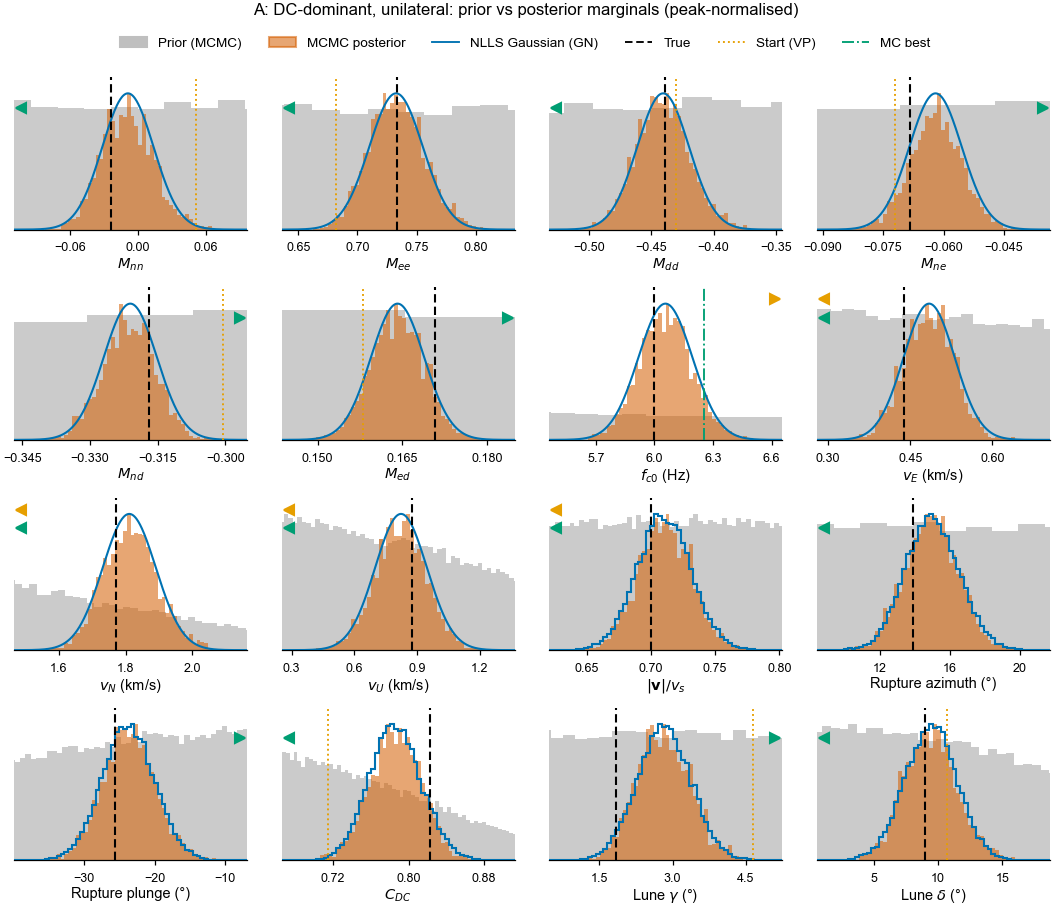

In [13]:
fig_marginals('A', 'fig03_A_marginals');

### 8.3 Moment tensors and lune
- **Top:** beachballs of the true source and of each method's best model, with $C_{DC}$, the Kagan angle K to the true source, and the lune position.
- **Bottom:** the lune (Hammer projection).
  - MC: the best 2 % of its samples (an ensemble from a global search; the likelihood weights themselves have an ESS of about 1);
  - NLLS: 20 000 Gauss–Newton draws;
  - MCMC: 16 000 posterior samples;
  - a zoom in $(\gamma, \delta)$ with 68 % (solid) and 95 % (dashed) HPD contours for NLLS and MCMC.
- **Markers:** best models and the truth. In the zoom, hollow markers are outside the plotted range and drawn on its edge.

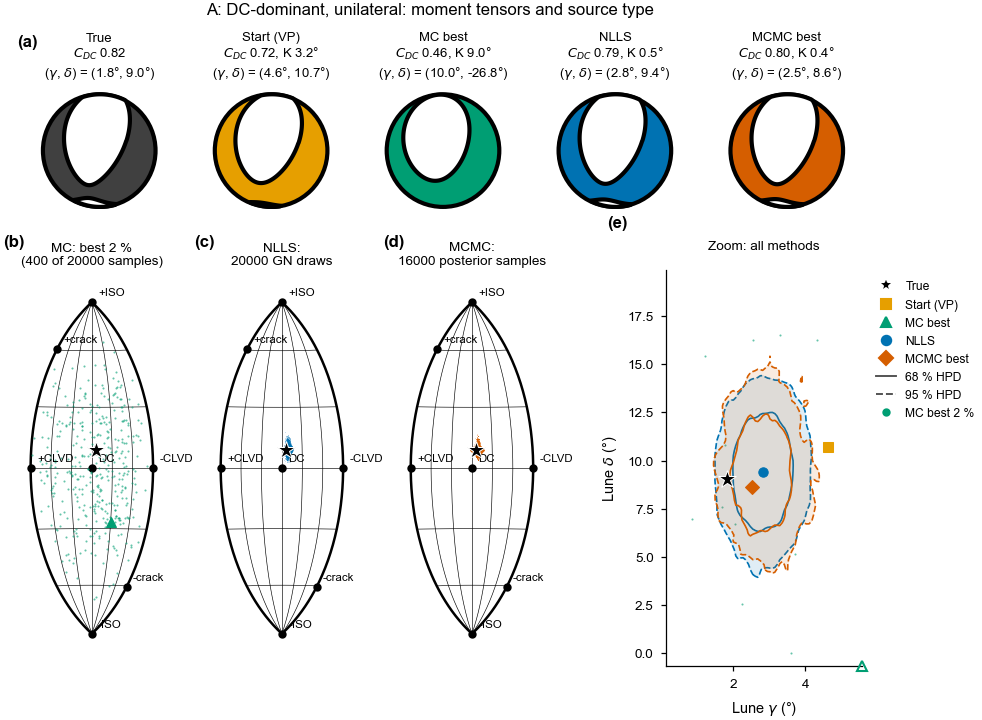

In [14]:
fig_mt('A', 'fig04_A_mt_lune');

### 8.4 Waveforms
- **Traces:** Z, R and T at the inner and outer ring, at the receivers closest to the rupture azimuth (forward) and opposite it (backward).
- **Lines:** the noisy data, the noise-free true waveform (thick grey), and each method's best model.
- **VR:** the legend gives the variance reduction over all traces. With noise at peak SNR 20, the true model itself reaches only the VR shown for it.

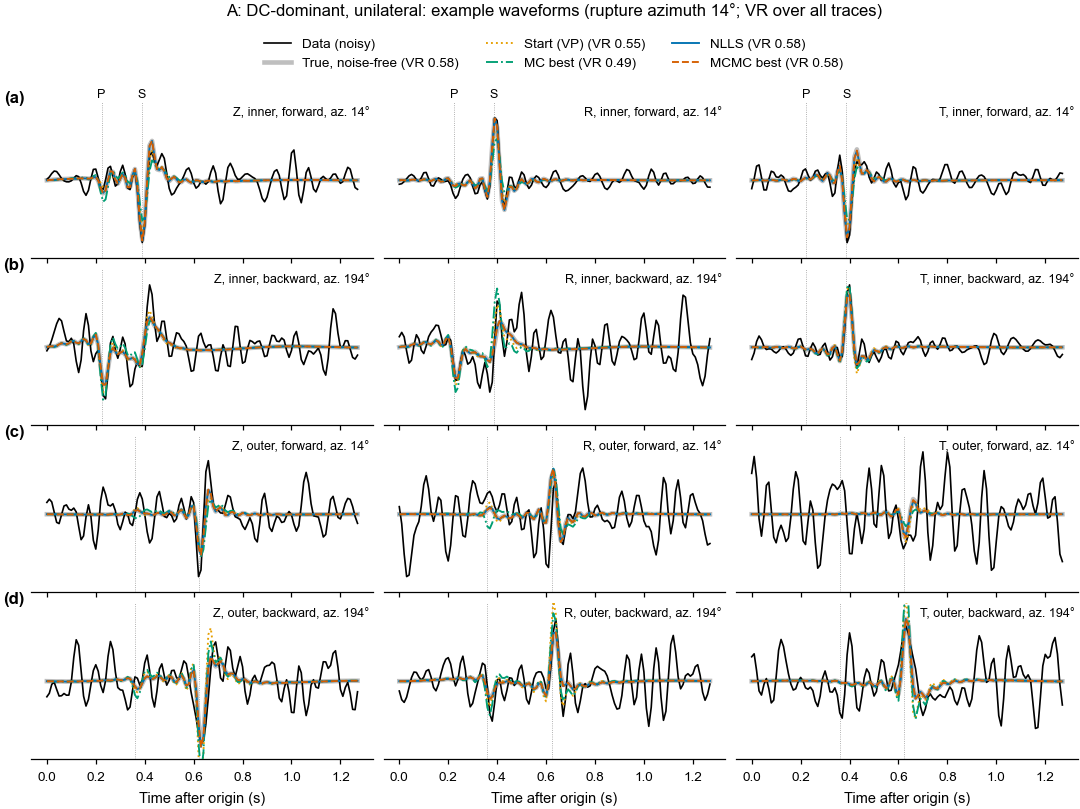

In [15]:
fig_waveforms('A', 'fig05_A_waveforms');

## 9. Source B: tensile-crack-dominant, unilateral rupture
- **The source.** The DC part is about 20 % of the moment, and only it carries directivity.
- **What to look for.** How well are $\mathbf{v}$ and its direction still constrained?
- **Trade-off.** Errors in the small DC part propagate into $\mathbf{v}$: to first order, $\delta|\mathbf{v}|/|\mathbf{v}| \approx -\delta C_{DC}/C_{DC}$.
### 9.1 Inversion

In [16]:
run_or_load('B')
summary_table('B').round(4)

source B: loaded cached inversion results from mt_dc_directivity_out/inversions_analytic.pkl
B: tensile-dominant, unilateral: times start 0.1 s, MC 38.9 s (ESS 1.0), NLLS 1.4 s (38 forward evals), MCMC 59.1 s; MCMC acceptance 0.26, max R-hat 1.010, ESS 488


,true,start,MC best,NLLS,NLLS sd (GN),MCMC mean,MCMC sd,R-hat,tau (steps)
Mnn,0.2298,0.2419,-0.5356,0.2504,0.0142,0.2497,0.0147,1.0038,32.7554
Mee,0.9249,0.8756,0.3080,0.9389,0.0176,0.9381,0.0178,1.0052,32.5725
Mdd,0.1215,0.0947,-0.6166,0.1374,0.0135,0.1367,0.0138,1.0053,30.8941
Mne,-0.0976,-0.0946,-0.1136,-0.0968,0.0045,-0.0969,0.0045,1.0033,29.2367
Mnd,-0.1002,-0.1057,-0.1265,-0.1002,0.0032,-0.1001,0.0033,1.0105,24.7747
Med,0.1376,0.1327,0.2121,0.1358,0.0032,0.1357,0.0033,1.0030,29.9202
fc0,6.0000,6.4365,4.3628,5.9215,0.0785,5.9232,0.0787,1.0034,27.9029
v_e,437.9923,0.0000,-1592.3857,400.5304,83.6309,397.6223,81.7365,1.0077,32.2539
v_n,1770.1250,0.0000,596.4154,1722.3446,126.0213,1724.5308,127.0451,1.0039,25.9842
v_u,875.9847,0.0000,703.9875,954.5040,125.5703,948.2145,124.9713,1.0051,25.8357


### 9.2 Prior vs posterior marginals

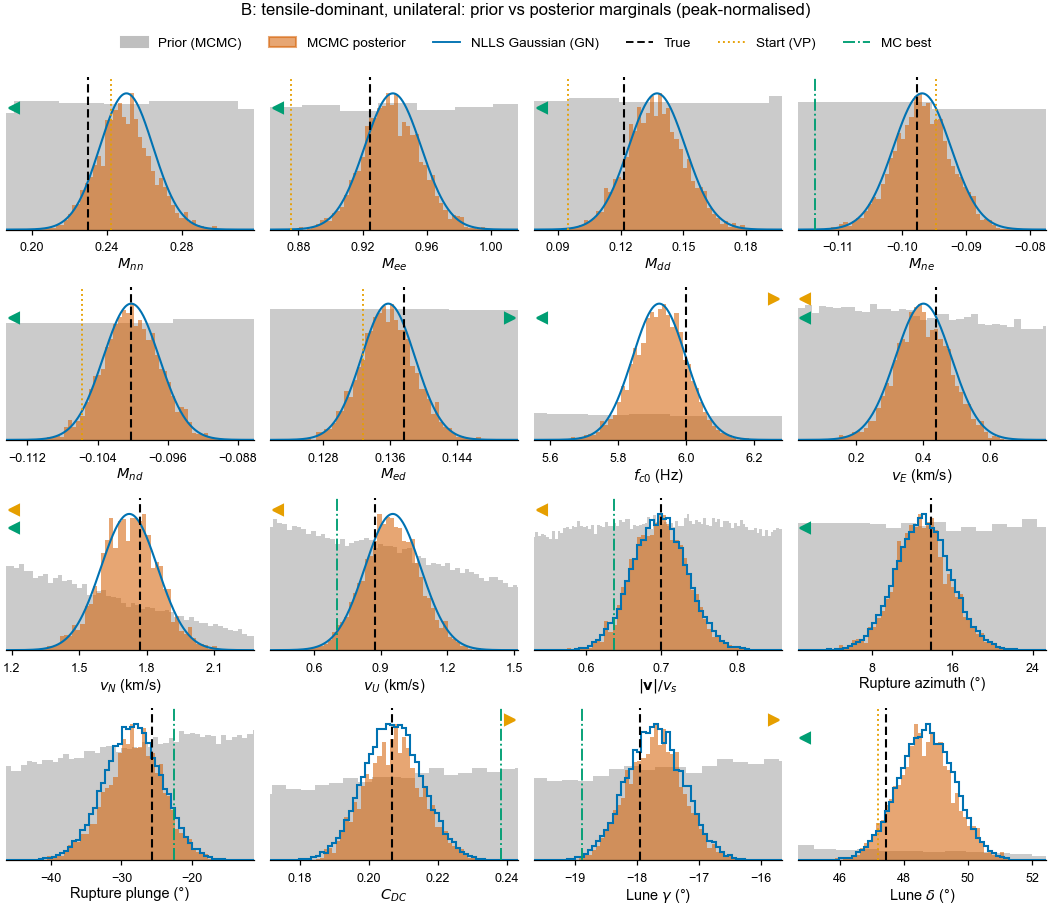

In [17]:
fig_marginals('B', 'fig06_B_marginals');

### 9.3 Moment tensors and lune

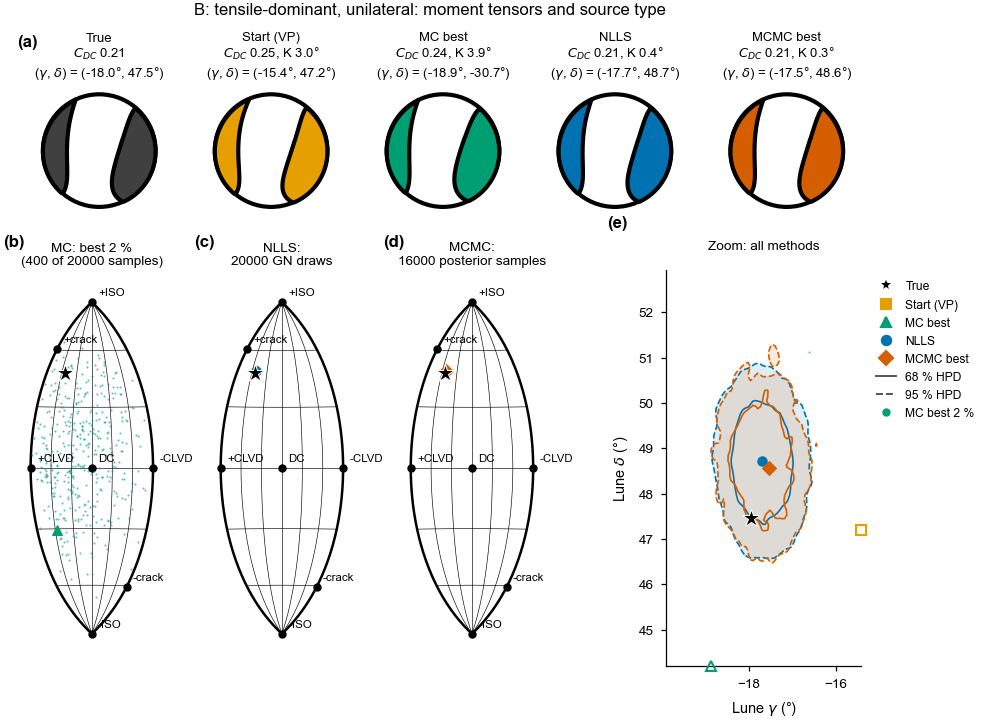

In [18]:
fig_mt('B', 'fig07_B_mt_lune');

### 9.4 Waveforms

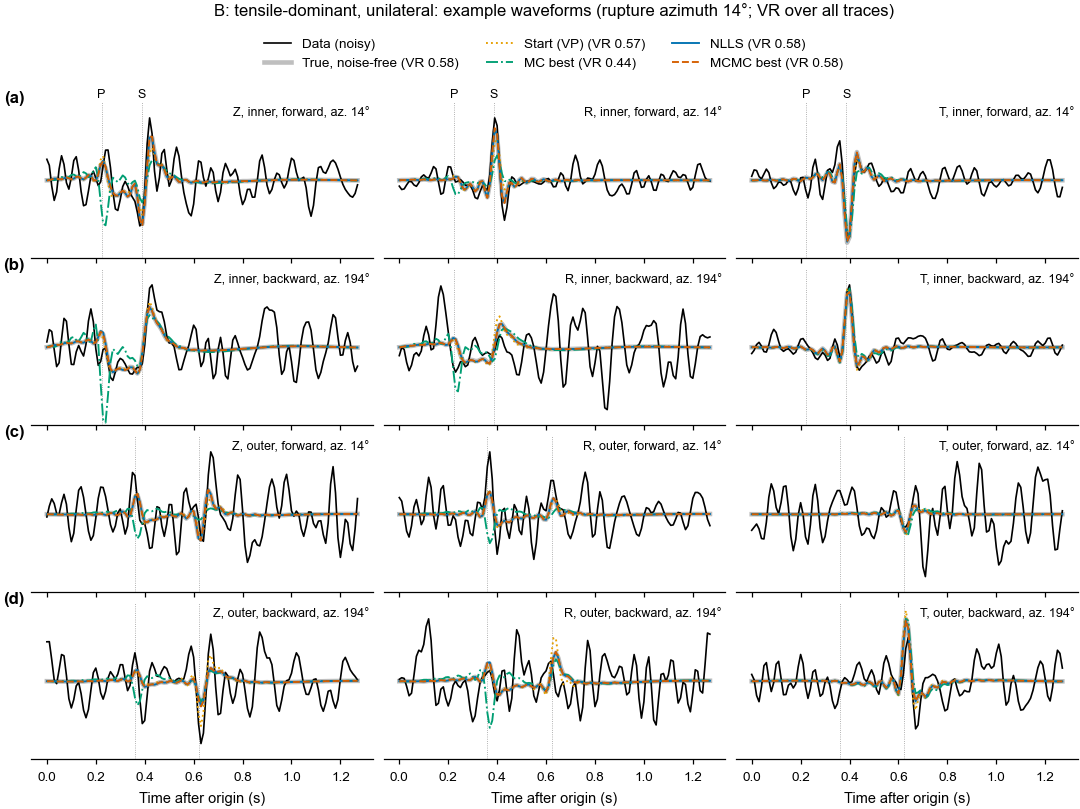

In [19]:
fig_waveforms('B', 'fig08_B_waveforms');

## 10. Source C: true bilateral rupture, inverted with the unilateral model
- **The data:** the MT of A, but the DC part ruptures bilaterally (section 1.4). The "true" $f_{c0}$ and $\mathbf{v}$ shown are those of the bilateral source: corner $2f_{c0}$ for each half, rupture velocity $\pm\mathbf{v}$. They are **not** parameters the unilateral model can reach.
- **Expected:** $f_{c0} \approx 12$ Hz, $|\mathbf{v}|$ small, and a well-recovered MT.
### 10.1 Inversion

In [20]:
run_or_load('C')
summary_table('C').round(4)

source C: loaded cached inversion results from mt_dc_directivity_out/inversions_analytic.pkl
C: DC-dominant, bilateral: times start 0.2 s, MC 39.4 s (ESS 1.0), NLLS 1.1 s (29 forward evals), MCMC 62.5 s; MCMC acceptance 0.26, max R-hat 1.013, ESS 465


,true,start,MC best,NLLS,NLLS sd (GN),MCMC mean,MCMC sd,R-hat,tau (steps)
Mnn,-0.0236,-0.0999,0.1801,-0.1084,0.0173,-0.1093,0.0180,1.0088,31.8587
Mee,0.7338,0.6333,0.8272,0.6347,0.0176,0.6341,0.0177,1.0092,30.3163
Mdd,-0.4387,-0.4662,-0.1670,-0.4652,0.0160,-0.4663,0.0167,1.0129,34.4106
Mne,-0.0682,-0.0746,0.0649,-0.0738,0.0059,-0.0737,0.0060,1.0065,30.5324
Mnd,-0.3169,-0.2860,-0.1928,-0.2861,0.0046,-0.2861,0.0045,1.0068,33.1241
Med,0.1709,0.1622,0.1191,0.1624,0.0043,0.1626,0.0039,1.0061,24.3873
fc0,6.0000,12.4248,13.0907,12.1531,0.3276,12.1712,0.3349,1.0077,33.3017
v_e,437.9923,0.0000,121.1165,122.1331,53.0057,123.6596,50.9852,1.0076,28.2131
v_n,1770.1250,0.0000,1059.2313,328.1571,75.9239,326.8911,76.6250,1.0118,28.9637
v_u,875.9847,0.0000,-1212.2595,168.6474,161.2550,157.1964,165.3269,1.0103,32.4092


### 10.2 Prior vs posterior marginals

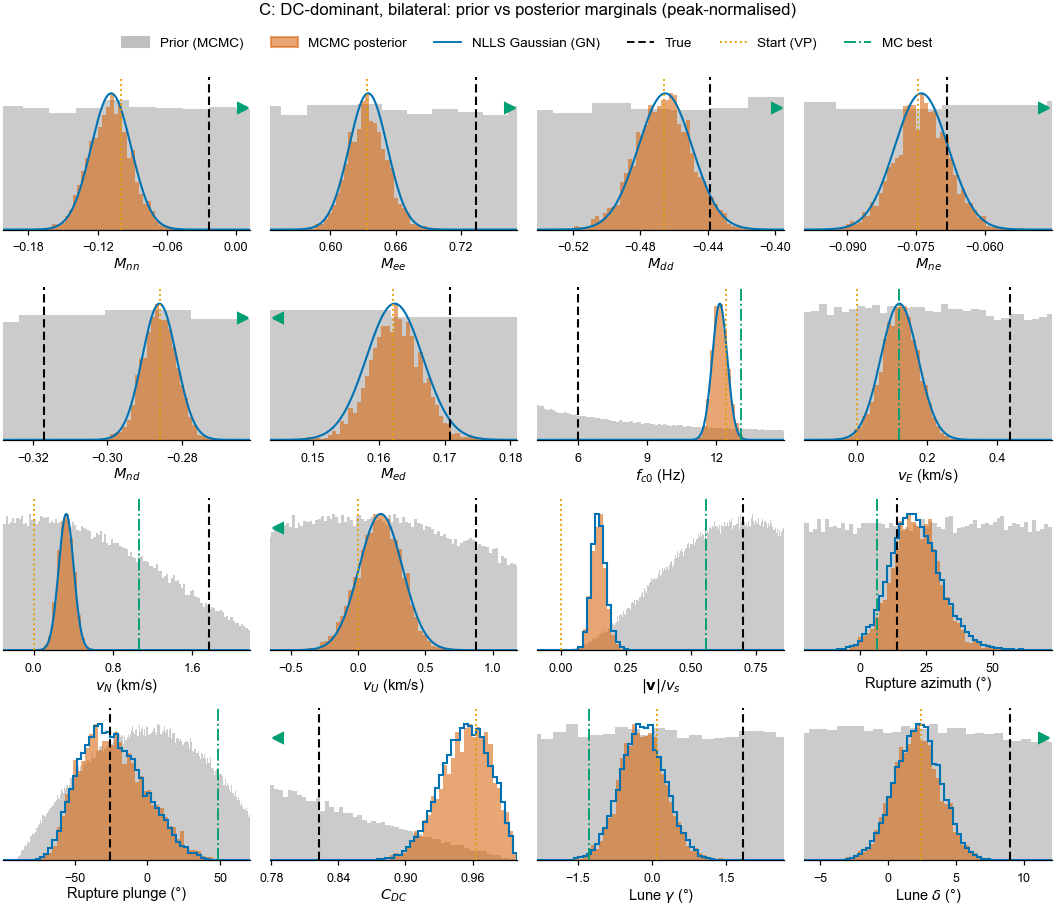

In [21]:
fig_marginals('C', 'fig09_C_marginals');

### 10.3 Moment tensors and lune

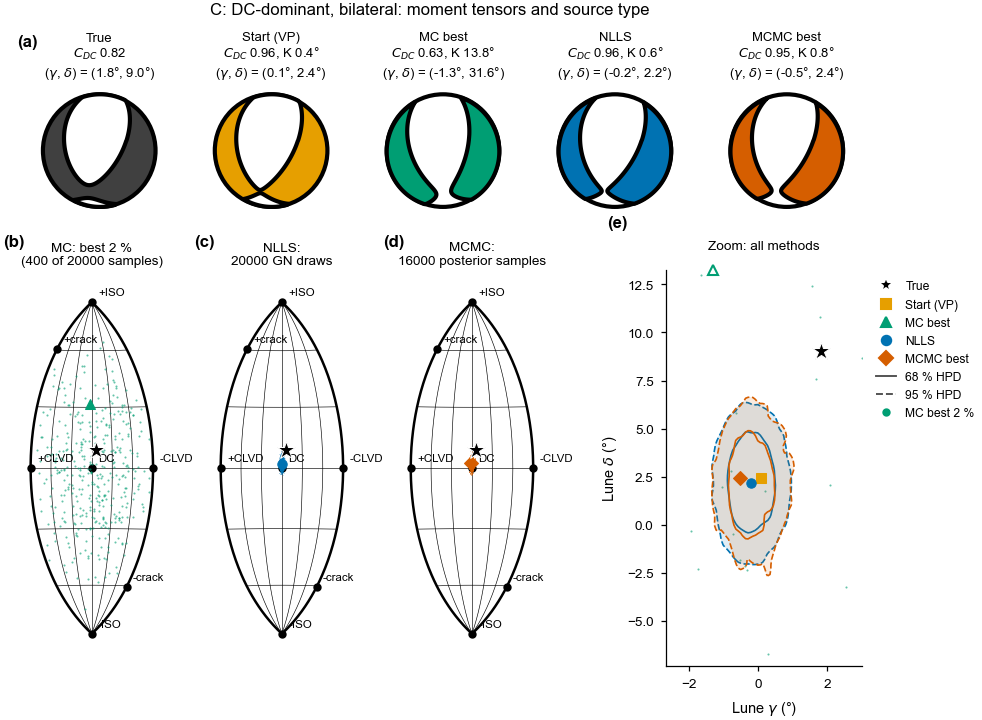

In [22]:
fig_mt('C', 'fig10_C_mt_lune');

### 10.4 Waveforms

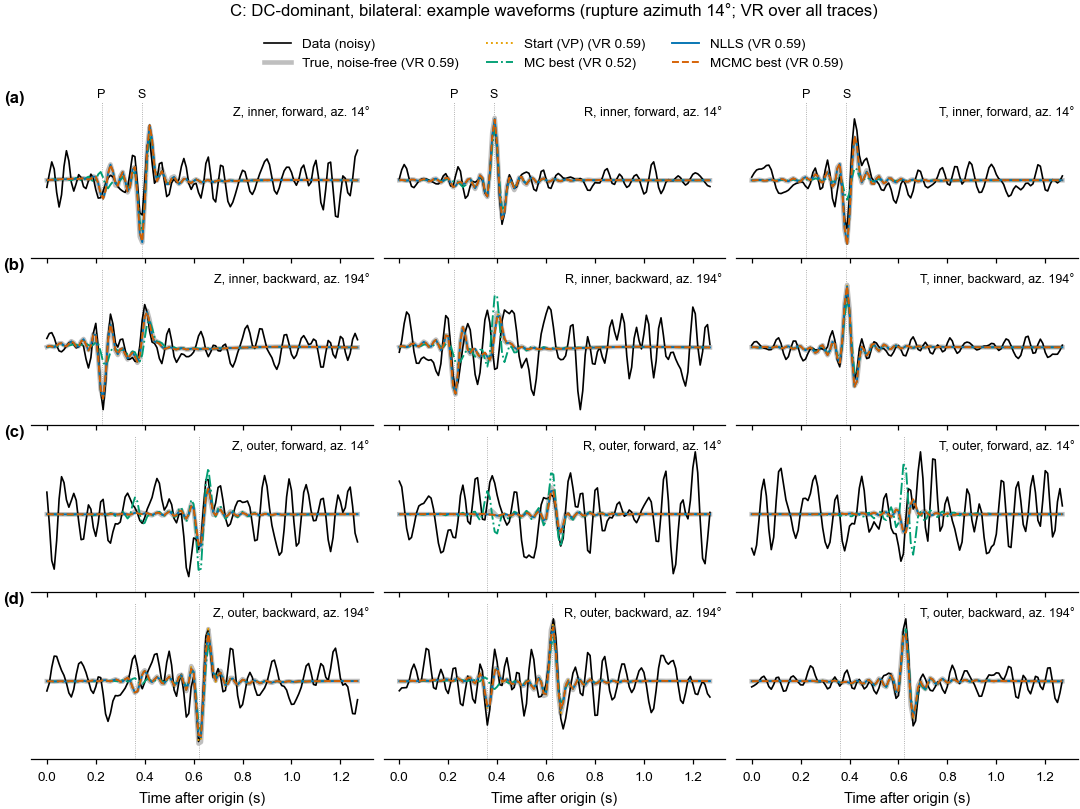

In [23]:
fig_waveforms('C', 'fig11_C_waveforms');

## 11. Summary across sources

### 11.1 Summary figure
One row per source, with three panels:
- **left:** the lune zoom (as in the per-source figures);
- **middle:** the horizontal rupture velocity $(v_E, v_N)$;
- **right:** the $f_{c0}$–$v_U$ plane, where the trade-off of section 3 ("Why these choices") appears.

Each panel shows the 68/95 % HPD contours of NLLS (blue) and MCMC (vermillion), the best 2 % of MC samples (green dots), every method's best model, and the truth. For source C, the black star marks the true bilateral parameters ($f_{c0}$ = 6 Hz, $+\mathbf{v}$). The dotted line marks $2f_{c0}$ = 12 Hz, the corner frequency expected from the first-order argument in section 1.4.

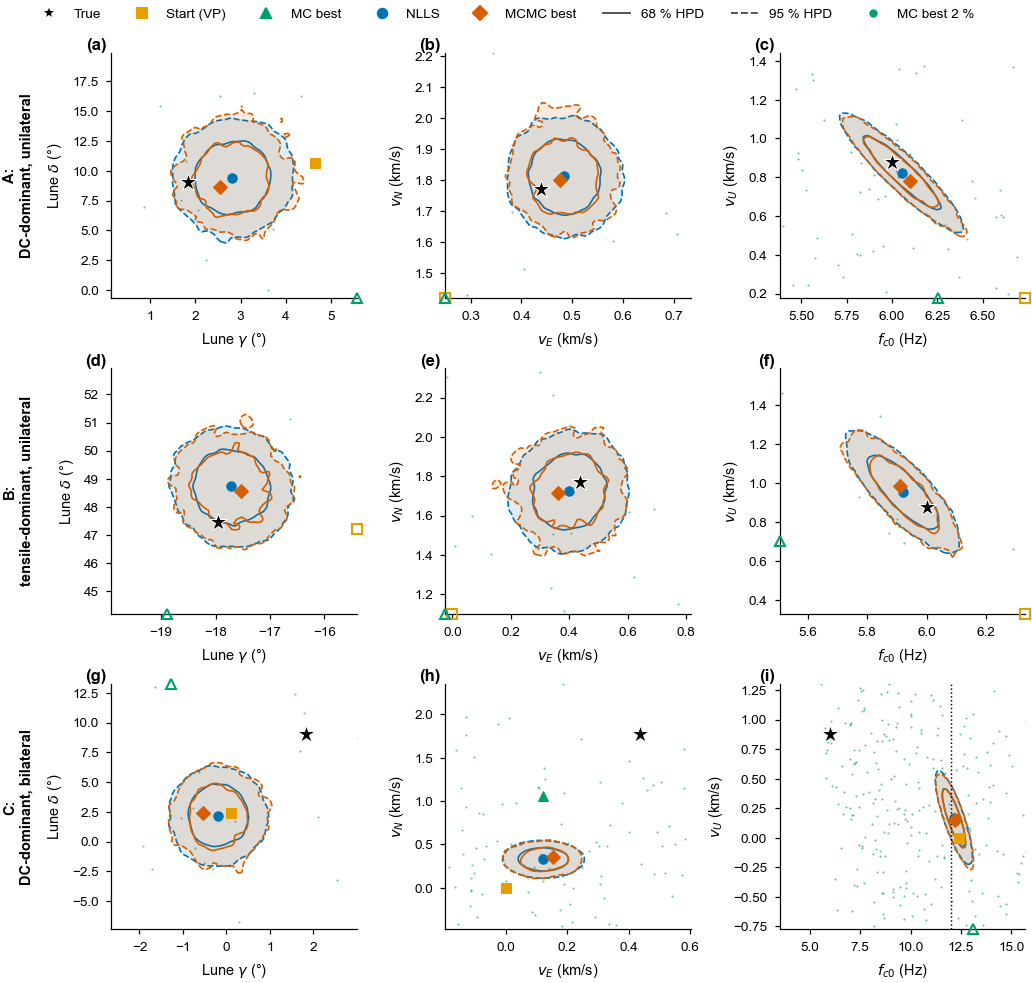

In [24]:
def plane_panel(ax, key, ix, iy, sx=1.0, sy=1.0, xlabel='', ylabel=''):
    R, S = INV[key], SOURCES[key]
    pm, pn = R['mcmc'].params, R['draws']
    top = R['mc'].top(int(0.02 * len(R['mc'])))
    xs = [pm[:, ix] * sx, pn[:, ix] * sx, [S['p_true'][ix] * sx] * 10]
    ys = [pm[:, iy] * sy, pn[:, iy] * sy, [S['p_true'][iy] * sy] * 10]
    xl, yl = sample_extent(xs, pad=0.35), sample_extent(ys, pad=0.35)
    ax.plot(R['mc'].params[top, ix] * sx, R['mc'].params[top, iy] * sy, '.', color=COLOR['MC'], ms=2.0, alpha=0.6,
            mew=0, zorder=1)
    hpd_contour(ax, pn[:, ix] * sx, pn[:, iy] * sy, COLOR['NLLS'], [xl, yl], fill=True)
    hpd_contour(ax, pm[:, ix] * sx, pm[:, iy] * sy, COLOR['MCMC'], [xl, yl], fill=True)
    for m, p in best_models(key).items():
        plot_point(ax, (p[ix] * sx, p[iy] * sy), m, clamp=(xl, yl))
    plot_point(ax, (S['p_true'][ix] * sx, S['p_true'][iy] * sy), 'true')
    ax.set(xlim=xl, ylim=yl, xlabel=xlabel, ylabel=ylabel)


fig, axes = plt.subplots(3, 3, figsize=(W2, 6.6))
for r, key in enumerate('ABC'):
    lune_zoom(axes[r, 0], key, legend=False)
    plane_panel(axes[r, 1], key, 7, 8, V_UNIT, V_UNIT, '$v_E$ (km/s)', '$v_N$ (km/s)')
    plane_panel(axes[r, 2], key, 6, 9, 1.0, V_UNIT, '$f_{c0}$ (Hz)', '$v_U$ (km/s)')
    if key == 'C':
        axes[r, 2].axvline(2 * FC0_TRUE, color='k', ls=':', lw=0.7)
    axes[r, 0].text(-0.38, 0.5, SOURCES[key]['title'].replace(': ', ':\n'), transform=axes[r, 0].transAxes,
                    rotation=90, ha='center', va='center', fontsize=7, fontweight='bold')
fig.legend(handles=method_handles(contours=True), loc='upper center', ncol=8, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0.02, 0, 1, 0.97), h_pad=1.0, w_pad=1.0)
label_panels(axes.ravel(), x=-0.02, y=1.0)
savefig(fig, 'fig12_summary_posteriors')

### 11.2 Performance of each method, for each source
For every source and method (best model):
- **Fit:** VR over all traces.
- **MT errors:** $\|\Delta\mathbf{m}\|/\|\mathbf{m}\|$ (Frobenius norm), and the Kagan angle K between principal axes.
- **Source type:** $C_{DC}$ and the lune position.
- **STF:** $f_{c0}$, $|\mathbf{v}|/v_s$, rupture azimuth and plunge, and $|\Delta\mathbf{v}|/v_s$.
- **Cost:** run time, forward evaluations and ESS. For MC, the time includes its own variable-projection start. The MCMC time excludes the NLLS run that initialises it.

The `true` rows give the true values. For source C, these are the bilateral source's parameters, which the unilateral model cannot represent exactly.

In [25]:
perf = {}
for key in 'ABC':
    R, S = INV[key], SOURCES[key]
    ds = S['ds']
    model = unshake.MTDCDirectivityModel(**KW, scale=R['scale'])
    cost = {'start': (R['t_start'], np.nan, np.nan), 'MC': (R['t_mc'], N_MC, R['mc'].ess),
            'NLLS': (R['t_nlls'], R['info']['nfev'], np.nan),
            'MCMC': (R['t_mcmc'], N_STEPS * N_CHAINS, R['mcmc'].meta['ess'])}
    for m, p in [('true', S['p_true'])] + list(best_models(key).items()):
        d = {k: v[0] for k, v in derived(p).items()}
        synth = S['d_clean'] if m == 'true' else model.forward(p, ds)[0]
        perf[(key, LABEL[m])] = {
            'VR': float(misfit.vr(ds.data, synth)),
            '|dm|/|m|': mt.norm(p[:6] - S['m']) / mt.norm(S['m']),
            'Kagan (deg)': 0.0 if m == 'true' else kagan(S['m'], p[:6]),
            'C_DC': d['cdc'], 'gamma (deg)': d['gamma'], 'delta (deg)': d['delta'], 'fc0 (Hz)': d['fc0'],
            '|v|/vs': d['vrel'], 'v az (deg)': d['az'], 'v plunge (deg)': d['plunge'],
            '|dv|/vs': np.linalg.norm(p[7:10] - S['p_true'][7:10]) / vs,
            'time (s)': cost[m][0] if m != 'true' else np.nan,
            'forward evals': cost[m][1] if m != 'true' else np.nan,
            'ESS': cost[m][2] if m != 'true' else np.nan}
tab_perf = pd.DataFrame(perf).T
tab_perf.index.names = ['source', 'model']
tab_perf.to_csv(FIG_DIR / 'table_performance.csv')
(tab_perf.style.format(precision=2, na_rep='')
 .to_latex(FIG_DIR / 'table_performance.tex', hrules=True, multirow_align='t'))
tab_perf.round(3)

VR  |dm|/|m|  Kagan (deg)   C_DC  gamma (deg)  \
source model                                                          
A      True        0.579     0.000        0.000  0.823        1.837   
       Start (VP)  0.553     0.096        3.163  0.715        4.642   
       MC best     0.489     0.644        8.990  0.457        9.993   
       NLLS        0.580     0.021        0.497  0.786        2.821   
       MCMC best   0.580     0.016        0.374  0.803        2.536   
B      True        0.576     0.000        0.000  0.207      -17.954   
       Start (VP)  0.568     0.058        2.997  0.253      -15.363   
       MC best     0.442     1.235        3.945  0.238      -18.886   
       NLLS        0.577     0.030        0.446  0.207      -17.711   
       MCMC best   0.577     0.024        0.302  0.210      -17.536   
C      True        0.595     0.000        0.000  0.823        1.837   
       Start (VP)  0.593     0.137        0.421  0.963        0.105   
       MC best     0.515     0.442       13.790  0.634       -1.282   
       NLLS        0.594     0.141        0.585  0.963       -0.182   
       MCMC best   0.594     0.140        0.763  0.947       -0.527   

                   delta (deg)  fc0 (Hz)  |v|/vs  v az (deg)  v plunge (deg)  \
source model                                                                   
A      True              9.017     6.000   0.700      13.898         -25.659   
       Start (VP)       10.686     7.089   0.000         NaN             NaN   
       MC best         -26.792     6.252   0.227     -90.332          32.582   
       NLLS              9.425     6.056   0.709      14.973         -23.720   
       MCMC best         8.644     6.101   0.698      14.788         -22.757   
B      True             47.462     6.000   0.700      13.898         -25.659   
       Start (VP)       47.205     6.437   0.000         NaN             NaN   
       MC best         -30.733     4.363   0.637     -69.467         -22.490   
       NLLS             48.723     5.921   0.695      13.091         -28.360   
       MCMC best        48.557     5.911   0.696      11.904         -29.361   
C      True              9.017     6.000   0.700      13.898         -25.659   
       Start (VP)        2.408    12.425   0.000         NaN             NaN   
       MC best          31.633    13.091   0.559       6.523          48.670   
       NLLS              2.184    12.153   0.134      20.414         -25.718   
       MCMC best         2.407    12.212   0.144      23.686         -21.204   

                   |dv|/vs  time (s)  forward evals      ESS  
source model                                                  
A      True          0.000       NaN            NaN      NaN  
       Start (VP)    0.700     0.150            NaN      NaN  
       MC best       0.821    38.919        20000.0    1.000  
       NLLS          0.028     1.315           38.0      NaN  
       MCMC best     0.037    58.770        32000.0  421.425  
B      True          0.000       NaN            NaN      NaN  
       Start (VP)    0.700     0.138            NaN      NaN  
       MC best       0.814    38.927        20000.0    1.000  
       NLLS          0.034     1.400           38.0      NaN  
       MCMC best     0.050    59.071        32000.0  488.469  
C      True          0.000       NaN            NaN      NaN  
       Start (VP)    0.700     0.151            NaN      NaN  
       MC best       0.771    39.360        20000.0    1.000  
       NLLS          0.566     1.120           29.0      NaN  
       MCMC best     0.559    62.485        32000.0  464.972

### 11.3 Uncertainty: NLLS vs MCMC
For the STF parameters and the derived rupture quantities, each method's estimate is given with its standard deviation. NLLS reports $\hat{\mathbf{p}} \pm$ GN σ; MCMC reports the posterior mean ± std and the 95 % credible interval. The table also gives the normalised error $z = (\text{estimate} - \text{true})/\sigma$ for each method. $|z| \lesssim 2$ means the truth is consistent with that uncertainty.

For source C, the "true" values are not parameters of the inverted model, so its $z$ values measure model error, not noise.

In [26]:
unc = {}
for key in 'ABC':
    R, S = INV[key], SOURCES[key]
    truth = {k: v[0] for k, v in derived(S['p_true']).items()}
    post, draws = derived(R['mcmc'].params), derived(R['draws'])
    nl = {k: v[0] for k, v in derived(R['p_hat']).items()}
    for q, lab in [('fc0', 'fc0 (Hz)'), ('v_e', 'v_E (km/s)'), ('v_n', 'v_N (km/s)'), ('v_u', 'v_U (km/s)'),
                   ('vrel', '|v|/vs'), ('az', 'v azimuth (deg)'), ('cdc', 'C_DC')]:
        sd_n = np.nanstd(draws[q])
        mean_m, sd_m = np.nanmean(post[q]), np.nanstd(post[q])
        lo, hi = np.nanpercentile(post[q], [2.5, 97.5])
        unc[(key, lab)] = {'true': truth[q], 'NLLS': nl[q], 'NLLS sd': sd_n, 'z NLLS': (nl[q] - truth[q]) / sd_n,
                           'MCMC mean': mean_m, 'MCMC sd': sd_m, 'MCMC 2.5 %': lo, 'MCMC 97.5 %': hi,
                           'z MCMC': (mean_m - truth[q]) / sd_m}
tab_unc = pd.DataFrame(unc).T
tab_unc.index.names = ['source', 'quantity']
tab_unc.to_csv(FIG_DIR / 'table_uncertainty.csv')
tab_unc.style.format(precision=3).to_latex(FIG_DIR / 'table_uncertainty.tex', hrules=True, multirow_align='t')
tab_unc.round(3)

true    NLLS  NLLS sd  z NLLS  MCMC mean  MCMC sd  \
source quantity                                                               
A      fc0 (Hz)          6.000   6.056    0.138   0.408      6.057    0.136   
       v_E (km/s)        0.438   0.484    0.046   1.003      0.484    0.046   
       v_N (km/s)        1.770   1.811    0.080   0.515      1.815    0.082   
       v_U (km/s)        0.876   0.824    0.124  -0.422      0.820    0.122   
       |v|/vs            0.700   0.709    0.021   0.409      0.711    0.020   
       v azimuth (deg)  13.898  14.973    1.525   0.705     14.954    1.507   
       C_DC              0.823   0.786    0.028  -1.335      0.786    0.027   
B      fc0 (Hz)          6.000   5.921    0.079  -0.998      5.923    0.079   
       v_E (km/s)        0.438   0.401    0.083  -0.451      0.398    0.082   
       v_N (km/s)        1.770   1.722    0.126  -0.378      1.725    0.127   
       v_U (km/s)        0.876   0.955    0.125   0.626      0.948    0.125   
       |v|/vs            0.700   0.695    0.036  -0.130      0.697    0.036   
       v azimuth (deg)  13.898  13.091    2.726  -0.296     13.017    2.731   
       C_DC              0.207   0.207    0.008   0.010      0.207    0.008   
C      fc0 (Hz)          6.000  12.153    0.328  18.769     12.171    0.335   
       v_E (km/s)        0.438   0.122    0.053  -5.982      0.124    0.051   
       v_N (km/s)        1.770   0.328    0.076 -18.999      0.327    0.077   
       v_U (km/s)        0.876   0.169    0.161  -4.387      0.157    0.165   
       |v|/vs            0.700   0.134    0.028 -19.991      0.145    0.028   
       v azimuth (deg)  13.898  20.414    9.772   0.667     21.197    9.189   
       C_DC              0.823   0.963    0.022   6.381      0.954    0.022   

                        MCMC 2.5 %  MCMC 97.5 %  z MCMC  
source quantity                                          
A      fc0 (Hz)              5.796        6.331   0.416  
       v_E (km/s)            0.395        0.573   1.011  
       v_N (km/s)            1.662        1.985   0.550  
       v_U (km/s)            0.572        1.061  -0.458  
       |v|/vs                0.672        0.752   0.533  
       v azimuth (deg)      12.087       17.871   0.701  
       C_DC                  0.732        0.837  -1.343  
B      fc0 (Hz)              5.761        6.073  -0.975  
       v_E (km/s)            0.235        0.556  -0.494  
       v_N (km/s)            1.468        1.981  -0.359  
       v_U (km/s)            0.705        1.196   0.578  
       |v|/vs                0.629        0.766  -0.080  
       v azimuth (deg)       7.711       18.472  -0.323  
       C_DC                  0.191        0.224   0.050  
C      fc0 (Hz)             11.527       12.882  18.425  
       v_E (km/s)            0.019        0.221  -6.165  
       v_N (km/s)            0.180        0.476 -18.835  
       v_U (km/s)           -0.181        0.465  -4.348  
       |v|/vs                0.094        0.203 -19.772  
       v azimuth (deg)       3.228       39.745   0.794  
       C_DC                  0.907        0.992   5.897

### 11.4 MCMC diagnostics

In [27]:
pd.DataFrame({key: {'acceptance': INV[key]['mcmc'].meta['acceptance'],
                    'max R-hat': np.nanmax(INV[key]['mcmc'].meta['rhat']),
                    'max tau (steps)': np.nanmax(INV[key]['mcmc'].meta['tau']),
                    'min ESS': INV[key]['mcmc'].meta['ess'],
                    'NLLS noise correlation factor': INV[key]['info']['noise_factor'],
                    'samples kept': len(INV[key]['mcmc'])} for key in 'ABC'}).T.round(3)

,acceptance,max R-hat,max tau (steps),min ESS,NLLS noise correlation factor,samples kept
A,0.253,1.010,37.966,421.425,2.513,16000.0
B,0.263,1.010,32.755,488.469,2.505,16000.0
C,0.257,1.013,34.411,464.972,2.519,16000.0


## 12. Discussion

Values quoted here (≈) are from the default run with the analytic full-space GFs. With `GF_SOURCE = 'salvus'` they change slightly, so check them against the tables in 11.2–11.4.

**Source A (DC-dominant, unilateral): the best case.**
- NLLS and MCMC recover every parameter within about 1σ: $f_{c0}$ ≈ 6.06 ± 0.14 Hz; $|\mathbf{v}|/v_s$ ≈ 0.71 ± 0.02; rupture azimuth ≈ 15 ± 1.5°.
- **$v_U$ is resolved:** ≈ 0.82 ± 0.12 km/s, against 0.88 true. The rays leave the source at two different take-off angles. The posteriors show the expected negative $f_{c0}$–$v_U$ correlation (Fig. 12c), which the two rings limit.
- **NLLS vs MCMC.** The GN Gaussian and the MCMC posterior are almost identical: the posterior is close to Gaussian at this SNR. The correlated-noise correction (factor ≈ 2.5) is needed for this agreement to be meaningful (see `directional_inversion_demo.ipynb`, section 4).
- **The starting model.** Variable projection with a single Brune STF and no directivity gets the MT orientation to within ≈ 3° (Kagan). Its $f_{c0}$ is biased high (≈ 7.1 Hz), since one symmetric STF has to fit the forward-directed, high-frequency DC radiation.
- **Monte Carlo is not useful in 10-D.** 20 000 prior samples give ESS ≈ 1. The best MC sample is far off: $C_{DC}$ ≈ 0.46, and the rupture direction is wrong. The 2 % best samples are spread over the whole lune.

**Source B (tensile-crack-dominant, $C_{DC}$ ≈ 0.21).**
- The MT, source type and $f_{c0}$ are recovered as well as for A, with $C_{DC}$ = 0.207 ± 0.008.
- **$\mathbf{v}$ is still well constrained** (σ ≈ 0.04 $v_s$ on $|\mathbf{v}|$, ≈ 3° in azimuth), although only about 20 % of the moment carries directivity. With dense, two-ring coverage at this SNR, the DC radiation lobes dominate enough receivers to fix $\mathbf{v}$.
- **The trade-off with $C_{DC}$.** A low-DC source is not automatically uninformative about directivity, but its $\mathbf{v}$ estimate depends directly on the accuracy of the small DC part: $\delta|\mathbf{v}|/|\mathbf{v}| \approx -\delta C_{DC}/C_{DC}$. A spurious CLVD from GF errors would bias $|\mathbf{v}|$ much more than for source A.
- **In the limit.** For a pure tensile crack ($C_{DC}$ = 0), the posterior of $\mathbf{v}$ reverts to the prior (`directional_inversion_demo.ipynb`, section 6).

**Source C (bilateral rupture, unilateral model): model error.**
- **$f_{c0}$:** ≈ 12.2 ± 0.3 Hz, i.e. ≈ $2f_{c0}$, the corner of each half-rupture. This is what the first-order cancellation argument of section 1.4 predicts.
- **$|\mathbf{v}|$:** collapses to ≈ 0.14 $v_s$ (against 0.7), pointing roughly along the true rupture axis (azimuth ≈ 21 ± 9°). This residual comes from the second-order, symmetric directivity, which the unilateral model can only partly mimic.
- **The MT is biased.** The unilateral model forces one $f_{c0}$ on the DC part (effectively 12 Hz) and on the non-DC part (truly 6 Hz). The inversion compensates by moving moment into the DC part: $C_{DC}$ ≈ 0.96 ± 0.02 against 0.82, and $\delta$ ≈ 2° against 9°. The DC orientation is barely affected (Kagan ≈ 0.6°).
- **Detection.** The fit is as good as that of the true model (VR ≈ 0.594 against 0.595 at this SNR), so the misfit cannot flag the model error. The posteriors are narrow and confidently wrong ($|z|$ up to ≈ 20).
- **In practice.**
  - A small $|\mathbf{v}|$ together with a high $f_{c0}$ is ambiguous: a compact source, or a bilateral rupture.
  - An apparent near-pure DC may partly reflect a mismatched STF.
  - A bilateral (or general two-sided) rupture mode is a natural model extension, and could be compared by Bayesian evidence.

**Methods.**
- NLLS takes about 1–2 s (≈ 30–40 forward evaluations from 5 starts). Its GN covariance matches the MCMC posterior for all three sources.
- MCMC (8 × 4000 steps, ≈ 1 min) gives ESS ≈ 400–500 with $\hat R$ ≤ 1.02. It adds a check of Gaussianity and respects the prior bounds. Its value is greatest when the posterior is non-Gaussian, e.g. for sources with almost no DC.

**Limitations of this synthetic test.**
- The same GFs and the same Doppler velocity ($c = v_p$) are used for the data and the inversion. There is no GF or velocity-model error, and no P/S-dependent Doppler.
- The STFs are point-source Brune functions.
- The receivers form a dense two-ring array with an ideal azimuthal distribution. Sparser or one-sided networks will constrain $\mathbf{v}$ less.